# EDA: ISIC 2024 Challenge — Skin Cancer Detection with 3D-TBP (бинарная классификация)

Соревнование: [isic-2024-challenge](https://www.kaggle.com/competitions/isic-2024-challenge/data)

**Задача:** по кропу родинки (изображение 15×15 мм из 3D Total Body Photography) + табличным метаданным предсказать вероятность того, что очаг — **злокачественная меланома** (`target = 1`).
**Метрика:** partial AUC (pAUC) в области `TPR >= 80%` (максимум = 0.20, случайный классификатор ≈ 0.02).

Ноутбук посвящён **табличным метаданным** (`train-metadata.csv`) — это основа для GBDT-моделей (LightGBM / XGBoost / CatBoost).

## Содержание

0. **Подготовка**: импорты, поиск/загрузка данных, группы признаков, реализация метрики pAUC
1. **Критический дисбаланс (target)**: точное соотношение классов, ловушка accuracy, поведение pAUC при экстремальном перекосе
2. **Аудит структуры пациентов**: родинок на пациента (min / max / mean), пациенты-выбросы
3. **Утечки и пересечения** (`patient_id` / `lesion_id`): train vs test, дубликаты, построение корректной `GroupKFold`-валидации
4. **Клинические признаки**: `age_approx`, `sex`, `anatom_site_general` в разрезе `target`
5. **Геометрические и цветовые признаки 3D-TBP**: диаметр, периметр, асимметрия, `tbp_lv_*`; BoxPlot и разделяющая способность
6. **Пропуски (NaN)**: доли, случайность vs связь со злокачественностью
7. **Мультиколлинеарность**: корреляционная матрица, кластеры дублирующих признаков, VIF, список признаков к удалению
8. **«Гадкий утёнок»** (Contextual EDA): отклонение признаков родинки от среднего/медианы пациента
9. **Итоги и рекомендации** для моделирования

> ⚠️ Колонки `lesion_id`, `iddx_*`, `mel_*`, `tbp_lv_dnn_lesion_confidence` присутствуют только в train и/или напрямую «знают» ответ.
> Они анализируются как источник утечки, но **не должны** попадать в признаки модели.

## 0. Подготовка

In [1]:
# 0.1 Импорты и настройки
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, StratifiedGroupKFold

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 13})
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

SEED = 42
RNG = np.random.default_rng(SEED)

ROOT = Path.cwd()                      # папка EDA (где лежит ноутбук)
CSV_DIR = ROOT / 'csv_outputs'         # все CSV
FIG_DIR = ROOT / 'figures'             # все картинки
for d in (CSV_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

COMPETITION = 'isic-2024-challenge'
PAL = {0: '#4C78A8', 1: '#E45756'}     # синий = benign, красный = melanoma
RUN_LEAK_DEMO = True                   # демонстрация завышения метрики при "нечестной" CV (раздел 3), ~1 мин


def save_fig(name):
    plt.savefig(FIG_DIR / f'isic2024_{name}.png', dpi=130, bbox_inches='tight')


print('ROOT    :', ROOT)
print('CSV_DIR :', CSV_DIR)
print('FIG_DIR :', FIG_DIR)

ROOT    : /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA
CSV_DIR : /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/csv_outputs
FIG_DIR : /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/figures


In [2]:
# 0.2 Поиск данных соревнования (скачиваем ТОЛЬКО метаданные, если их ещё нет)
def locate_file(name):
    bases = [ROOT / 'isic2024',
             Path.home() / '.cache' / 'kagglehub' / 'competitions' / COMPETITION]
    for base in bases:
        if (base / name).exists():
            return base / name
    return None


def get_file(name):
    path = locate_file(name)
    if path is None:
        import kagglehub
        print(f'📥 {name} не найден локально, скачиваем только этот файл через kagglehub...')
        path = Path(kagglehub.competition_download(COMPETITION, path=name))
    return path


TRAIN_PATH = get_file('train-metadata.csv')
TEST_PATH = locate_file('test-metadata.csv')      # в соревновании тест скрытый -> обычно None
SUB_PATH = locate_file('sample_submission.csv')   # публичный пример сабмита (3 строки)

df = pd.read_csv(TRAIN_PATH, low_memory=False)
print('train-metadata:', TRAIN_PATH)
print('test-metadata :', TEST_PATH)
print('shape         :', df.shape)
df.head(3).T

train-metadata: /home/dzmitry_tsetsiaruk/.cache/kagglehub/competitions/isic-2024-challenge/train-metadata.csv
test-metadata : None
shape         : (401059, 55)


,0,1,2
isic_id,ISIC_0015670,ISIC_0015845,ISIC_0015864
target,0,0,0
patient_id,IP_1235828,IP_8170065,IP_6724798
age_approx,60.0000,60.0000,60.0000
sex,male,male,male
anatom_site_general,lower extremity,head/neck,posterior torso
clin_size_long_diam_mm,3.0400,1.1000,3.4000
image_type,TBP tile: close-up,TBP tile: close-up,TBP tile: close-up
tbp_tile_type,3D: white,3D: white,3D: XP
tbp_lv_A,20.2444,31.7126,22.5758


In [3]:
# 0.3 Группы признаков
TARGET = 'target'

# Колонки, которые есть только в train / напрямую кодируют диагноз -> НЕЛЬЗЯ использовать как признаки
LEAK_COLS = [c for c in ['lesion_id', 'iddx_full', 'iddx_1', 'iddx_2', 'iddx_3', 'iddx_4', 'iddx_5',
                         'mel_mitotic_index', 'mel_thick_mm', 'tbp_lv_dnn_lesion_confidence'] if c in df.columns]

GEOM_COLS = ['clin_size_long_diam_mm', 'tbp_lv_minorAxisMM', 'tbp_lv_areaMM2', 'tbp_lv_perimeterMM',
             'tbp_lv_area_perim_ratio', 'tbp_lv_eccentricity', 'tbp_lv_symm_2axis',
             'tbp_lv_symm_2axis_angle', 'tbp_lv_norm_border']

COLOR_COLS = ['tbp_lv_A', 'tbp_lv_Aext', 'tbp_lv_B', 'tbp_lv_Bext', 'tbp_lv_C', 'tbp_lv_Cext',
              'tbp_lv_H', 'tbp_lv_Hext', 'tbp_lv_L', 'tbp_lv_Lext',
              'tbp_lv_deltaA', 'tbp_lv_deltaB', 'tbp_lv_deltaL', 'tbp_lv_deltaLB', 'tbp_lv_deltaLBnorm',
              'tbp_lv_color_std_mean', 'tbp_lv_norm_color', 'tbp_lv_radial_color_std_max',
              'tbp_lv_stdL', 'tbp_lv_stdLExt']

MISC_COLS = ['tbp_lv_nevi_confidence', 'tbp_lv_x', 'tbp_lv_y', 'tbp_lv_z']   # уверенность "невус" + 3D-координаты на теле

NUM_FEATURES = ['age_approx'] + GEOM_COLS + COLOR_COLS + MISC_COLS
CAT_FEATURES = ['sex', 'anatom_site_general', 'tbp_lv_location', 'tbp_lv_location_simple', 'tbp_tile_type', 'image_type']

not_found = [c for c in NUM_FEATURES + CAT_FEATURES + [TARGET, 'patient_id', 'isic_id'] if c not in df.columns]
assert not not_found, f'Нет колонок: {not_found}'

print(f'Числовых признаков : {len(NUM_FEATURES)}  (геометрия {len(GEOM_COLS)}, цвет {len(COLOR_COLS)}, прочие {len(MISC_COLS)}, возраст 1)')
print(f'Категориальных     : {len(CAT_FEATURES)}')
print(f'Train-only / leak  : {LEAK_COLS}')

Числовых признаков : 34  (геометрия 9, цвет 20, прочие 4, возраст 1)
Категориальных     : 6
Train-only / leak  : ['lesion_id', 'iddx_full', 'iddx_1', 'iddx_2', 'iddx_3', 'iddx_4', 'iddx_5', 'mel_mitotic_index', 'mel_thick_mm', 'tbp_lv_dnn_lesion_confidence']


In [4]:
# 0.4 Метрика соревнования: pAUC по области TPR >= 0.80 (официальная реализация) + вспомогательные функции
def comp_pauc(y_true, y_score, min_tpr=0.80):
    # Метки инвертируются, чтобы "FPR <= 0.2" в перевёрнутой задаче соответствовал "TPR >= 0.8" по меланоме
    v_gt = 1 - np.asarray(y_true)
    v_pred = -np.asarray(y_score, dtype=float)
    max_fpr = 1 - min_tpr
    fpr, tpr, _ = roc_curve(v_gt, v_pred)
    stop = np.searchsorted(fpr, max_fpr, 'right')
    x_interp = [fpr[stop - 1], fpr[stop]]
    y_interp = [tpr[stop - 1], tpr[stop]]
    tpr = np.append(tpr[:stop], np.interp(max_fpr, x_interp, y_interp))
    fpr = np.append(fpr[:stop], max_fpr)
    return auc(fpr, tpr)


def univariate_scores(y_true, x):
    # Разделяющая способность ОДНОГО признака: ROC AUC и pAUC с автоматическим выбором направления.
    # Возвращает (auc >= 0.5, знак направления, pAUC)
    y_true = np.asarray(y_true)
    x = np.asarray(x, dtype=float)
    ok = ~np.isnan(x)
    y_, x_ = y_true[ok], x[ok]
    a = roc_auc_score(y_, x_)
    sign = 1 if a >= 0.5 else -1
    return max(a, 1 - a), sign, comp_pauc(y_, sign * x_)


print('Проверка pAUC: идеальный =', round(comp_pauc([0, 0, 1, 1], [0.1, 0.2, 0.8, 0.9]), 4),
      '| инвертированный =', round(comp_pauc([0, 0, 1, 1], [0.9, 0.8, 0.2, 0.1]), 4))

Проверка pAUC: идеальный = 0.2 | инвертированный = 0.0


---
## 1. Анализ критического дисбаланса (Target)

Что делаем:
* считаем точное соотношение классов;
* показываем, почему accuracy бесполезна;
* изучаем поведение метрики **pAUC** при экстремальном перекосе: чему равны случайный и идеальный классификаторы и насколько pAUC шумит при малом числе позитивов.

Всего кропов (родинок)          : 401,059
target = 0 (доброкачественные)  : 400,666  (99.9020%)
target = 1 (меланома)           : 393  (0.0980%)
Imbalance ratio (neg : pos)     : 1,019.5 : 1
Позитивный класс < 0.1 % выборки: True

Связь target и диагноза iddx_1 (проверка корректности разметки):
target              0    1
iddx_1                    
Benign         400552    0
Indeterminate     114    0
Malignant           0  393


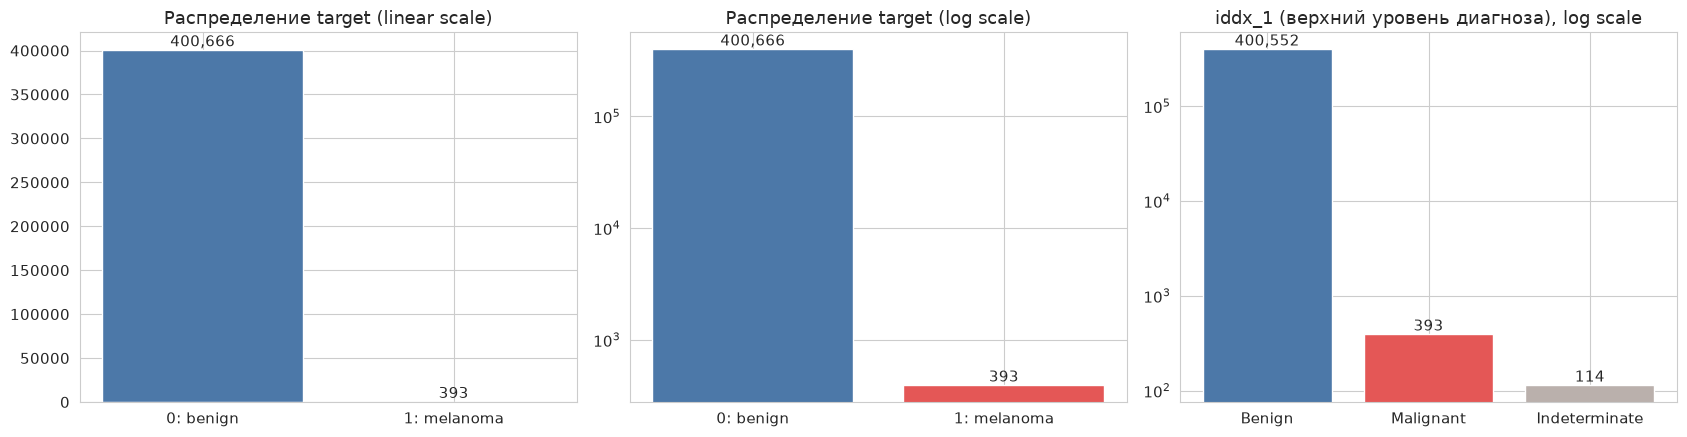

In [5]:
# 1.1 Точное соотношение классов
y = df[TARGET].to_numpy()
counts = df[TARGET].value_counts().sort_index()
n_total = len(df)
n_neg, n_pos = int(counts.loc[0]), int(counts.loc[1])
PREVALENCE = n_pos / n_total

print(f'Всего кропов (родинок)          : {n_total:,}')
print(f'target = 0 (доброкачественные)  : {n_neg:,}  ({n_neg / n_total:.4%})')
print(f'target = 1 (меланома)           : {n_pos:,}  ({PREVALENCE:.4%})')
print(f'Imbalance ratio (neg : pos)     : {n_neg / n_pos:,.1f} : 1')
print(f'Позитивный класс < 0.1 % выборки: {PREVALENCE < 0.001}')
print('\nСвязь target и диагноза iddx_1 (проверка корректности разметки):')
print(pd.crosstab(df['iddx_1'], df[TARGET]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
labels = ['0: benign', '1: melanoma']
for ax, scale in zip(axes[:2], ['linear', 'log']):
    ax.bar(labels, counts.values, color=[PAL[0], PAL[1]])
    ax.set_yscale(scale)
    ax.set_title(f'Распределение target ({scale} scale)')
    for i, v in enumerate(counts.values):
        ax.text(i, v, f'{v:,}', ha='center', va='bottom')
iddx = df['iddx_1'].value_counts()
axes[2].bar(iddx.index, iddx.values, color=['#4C78A8', '#E45756', '#BAB0AC'][:len(iddx)])
axes[2].set_yscale('log')
axes[2].set_title('iddx_1 (верхний уровень диагноза), log scale')
for i, v in enumerate(iddx.values):
    axes[2].text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout()
save_fig('01_class_balance')
plt.show()

In [6]:
# 1.2 Ловушка accuracy: "тупой" классификатор, который всегда говорит "доброкачественная"
const_scores = np.zeros(n_total)
rand_scores = RNG.random(n_total)

trap = pd.DataFrame({
    'метрика': ['Accuracy', 'Balanced accuracy', 'Recall по меланоме', 'ROC AUC', 'pAUC (TPR >= 80%)'],
    'константа "всё benign"': [n_neg / n_total, 0.5, 0.0, 0.5, comp_pauc(y, const_scores)],
    'случайные скоры': [np.nan, np.nan, np.nan, roc_auc_score(y, rand_scores), comp_pauc(y, rand_scores)],
})
trap

,метрика,"константа ""всё benign""",случайные скоры
0,Accuracy,0.9990,NaN
1,Balanced accuracy,0.5000,NaN
2,Recall по меланоме,0.0000,NaN
3,ROC AUC,0.5000,0.5050
4,pAUC (TPR >= 80%),0.0200,0.0233


In [7]:
# 1.3 Диапазон pAUC: идеальный и случайный классификаторы
rand_pauc = [comp_pauc(y, RNG.random(n_total)) for _ in range(30)]
print(f'Идеальный классификатор : {comp_pauc(y, y.astype(float)):.4f}   (теоретический максимум 0.2000)')
print(f'Случайный классификатор : {np.mean(rand_pauc):.4f} ± {np.std(rand_pauc):.4f}   (теория: 0.2² / 2 = 0.0200)')
print('\n=> Рабочий диапазон метрики очень узкий: [0.02 ... 0.20]. Разницу в 0.002 между моделями надо интерпретировать осторожно.')

Идеальный классификатор : 0.2000   (теоретический максимум 0.2000)
Случайный классификатор : 0.0197 ± 0.0021   (теория: 0.2² / 2 = 0.0200)

=> Рабочий диапазон метрики очень узкий: [0.02 ... 0.20]. Разницу в 0.002 между моделями надо интерпретировать осторожно.


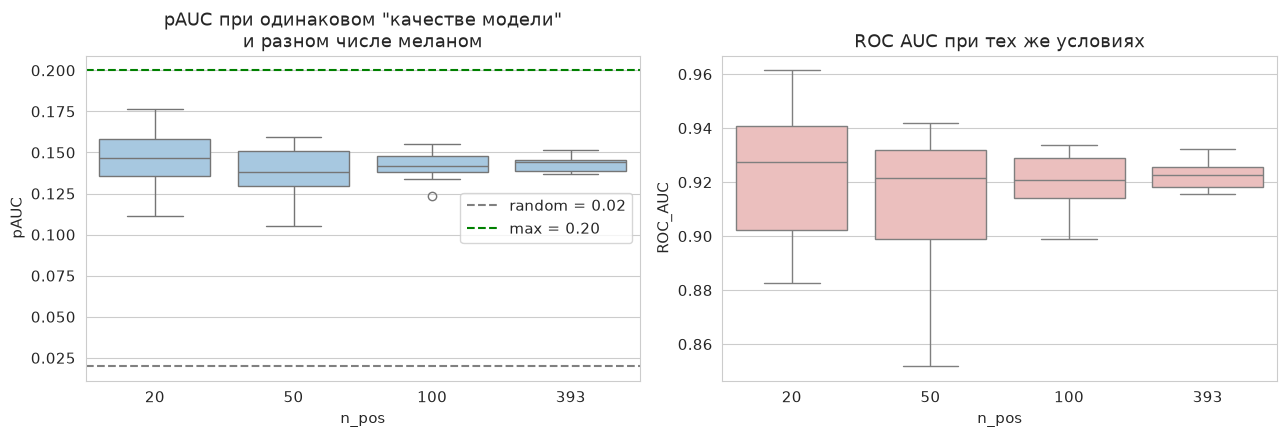

pAUC        ROC_AUC       
        mean    std    mean    std
n_pos                             
20    0.1462 0.0179  0.9232 0.0253
50    0.1379 0.0155  0.9134 0.0249
100   0.1427 0.0078  0.9206 0.0101
393   0.1432 0.0045  0.9223 0.0050

In [8]:
# 1.4 Насколько метрика шумит при малом числе позитивов?
# Симуляция: фиксированный "сигнал" (сдвиг гауссианы между классами), число негативов как в train,
# меняем только количество меланом. ROC AUC для сдвига 2.0 ≈ 0.92.
SIM_SHIFT = 2.0
N_REP = 20
sim_rows = []
for n_pos_sim in [20, 50, 100, n_pos]:
    for _ in range(N_REP):
        yy = np.r_[np.zeros(n_neg, dtype=int), np.ones(n_pos_sim, dtype=int)]
        ss = np.r_[RNG.normal(0, 1, n_neg), RNG.normal(SIM_SHIFT, 1, n_pos_sim)]
        sim_rows.append({'n_pos': n_pos_sim, 'pAUC': comp_pauc(yy, ss), 'ROC_AUC': roc_auc_score(yy, ss)})
sim = pd.DataFrame(sim_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=sim, x='n_pos', y='pAUC', ax=axes[0], color='#9ecae9')
axes[0].axhline(0.02, ls='--', c='gray', label='random = 0.02')
axes[0].axhline(0.20, ls='--', c='green', label='max = 0.20')
axes[0].set_title('pAUC при одинаковом "качестве модели"\nи разном числе меланом')
axes[0].legend()
sns.boxplot(data=sim, x='n_pos', y='ROC_AUC', ax=axes[1], color='#f2b8b7')
axes[1].set_title('ROC AUC при тех же условиях')
plt.tight_layout()
save_fig('01_pauc_noise')
plt.show()

sim.groupby('n_pos')[['pAUC', 'ROC_AUC']].agg(['mean', 'std'])

In [9]:
# 1.5 Реальный референс: bootstrap-доверительный интервал pAUC для готовых "скоров" из метаданных
# tbp_lv_dnn_lesion_confidence — выход собственной нейросети TBP (в train есть, для честной модели использовать нельзя),
# tbp_lv_nevi_confidence — уверенность, что очаг "невус" (чем выше, тем меньше шанс меланомы).
N_BOOT = 20
boot_rows = []
for col in [c for c in ['tbp_lv_dnn_lesion_confidence', 'tbp_lv_nevi_confidence'] if c in df.columns]:
    x = df[col].to_numpy(dtype=float)
    a_full, sign, p_full = univariate_scores(y, x)
    boots = []
    for _ in range(N_BOOT):
        idx = RNG.integers(0, n_total, n_total)
        boots.append(comp_pauc(y[idx], sign * x[idx]))
    boot_rows.append({'score': col, 'ROC_AUC': a_full, 'pAUC_full': p_full,
                      'pAUC_boot_mean': np.mean(boots),
                      'CI95_low': np.percentile(boots, 2.5), 'CI95_high': np.percentile(boots, 97.5)})
pd.DataFrame(boot_rows)

,score,ROC_AUC,pAUC_full,pAUC_boot_mean,CI95_low,CI95_high
0,tbp_lv_dnn_lesion_confidence,0.6865,0.0486,0.0490,0.0423,0.0591
1,tbp_lv_nevi_confidence,0.6457,0.0366,0.0362,0.0280,0.0469


### Выводы по разделу 1

* Позитивный класс — **393 меланомы на ~400 тыс. доброкачественных очагов (< 0.1 %)**, соотношение ≈ 1 : 1000.
* `Accuracy` бессмысленна: константа «всё benign» даёт ≈ 99.9 %, но ни одной найденной меланомы. Нужны ранговые метрики (pAUC / AUC), а не пороговые.
* pAUC лежит в диапазоне **[0.02; 0.20]**: случайный предсказатель ≈ 0.02, идеальный — 0.20. Метрика концентрируется на «высокочувствительном» хвосте ROC (TPR ≥ 80 %), поэтому важнее всего *ранжирование самых подозрительных очагов* среди сотен тысяч невусов.
* Симуляция показывает, что при таком малом числе позитивов pAUC заметно «шумит» → **нужна стратифицированная CV по группам (раздел 3), усреднение по нескольким сидам/фолдам, и нельзя гнаться за 3-м знаком после запятой**.
* Для обучения: undersampling негативов (например 1 : 10…1 : 50), `scale_pos_weight`, focal loss; при ранговой метрике калибровка вероятностей не нужна.

---
## 2. Аудит структуры пациентов (`patient_id`)

Один пациент = сотни «родинок» (кропов) с одного 3D-снимка тела. Считаем `min / max / mean / median` числа очагов на пациента и ищем пациентов-выбросов.

In [10]:
# 2.1 Сводка по пациентам
print('Пропусков в patient_id:', df['patient_id'].isna().sum())

patient = (df.groupby('patient_id')
             .agg(n_lesions=('isic_id', 'size'), n_melanoma=(TARGET, 'sum'), age_median=('age_approx', 'median'))
             .reset_index())
patient['has_melanoma'] = patient['n_melanoma'] > 0
patient['melanoma_rate'] = patient['n_melanoma'] / patient['n_lesions']
n_patients = len(patient)

print(f'Уникальных пациентов: {n_patients}')
print(f'Родинок на пациента : min={patient.n_lesions.min()}, max={patient.n_lesions.max()}, '
      f'mean={patient.n_lesions.mean():.1f}, median={patient.n_lesions.median():.0f}, std={patient.n_lesions.std():.1f}')
patient['n_lesions'].describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99]).to_frame('n_lesions').T

Пропусков в patient_id: 0
Уникальных пациентов: 1042
Родинок на пациента : min=1, max=9184, mean=384.9, median=242, std=540.3


,count,mean,std,min,1%,5%,25%,50%,75%,90%,95%,99%,max
n_lesions,"1,042.0000",384.8935,540.2689,1.0000,7.0000,26.0000,115.0000,241.5000,477.5000,822.9000,"1,122.6500","2,157.5800","9,184.0000"


In [11]:
# 2.2 Пациенты-выбросы по числу очагов (правило Тьюки: > Q3 + 1.5 * IQR) и по 99-му перцентилю
q1, q3 = patient.n_lesions.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
p99 = patient.n_lesions.quantile(0.99)
patient['is_outlier'] = patient['n_lesions'] > upper_fence

print(f'Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}, верхняя граница Тьюки={upper_fence:.0f}, P99={p99:.0f}')
cmp_out = (patient.groupby('is_outlier')
                  .agg(patients=('patient_id', 'size'), lesions=('n_lesions', 'sum'),
                       melanomas=('n_melanoma', 'sum'), median_lesions=('n_lesions', 'median')))
cmp_out['share_of_all_lesions'] = cmp_out['lesions'] / n_total
cmp_out['melanoma_per_mille'] = 1000 * cmp_out['melanomas'] / cmp_out['lesions']
display(cmp_out)

print('\nТоп-10 пациентов по числу очагов:')
display(patient.sort_values('n_lesions', ascending=False).head(10)[['patient_id', 'n_lesions', 'n_melanoma', 'melanoma_rate', 'age_median']])

Q1=115, Q3=478, IQR=362, верхняя граница Тьюки=1021, P99=2158


,patients,lesions,melanomas,median_lesions,share_of_all_lesions,melanoma_per_mille
is_outlier,,,,,,
False,980,288730,327,223.0000,0.7199,1.1325
True,62,112329,66,"1,387.0000",0.2801,0.5876



Топ-10 пациентов по числу очагов:


,patient_id,n_lesions,n_melanoma,melanoma_rate,age_median
103,IP_1117889,9184,0,0.0000,55.0000
566,IP_5714646,6267,1,0.0002,40.0000
379,IP_3921915,5568,1,0.0002,50.0000
811,IP_7797815,4454,2,0.0004,75.0000
1002,IP_9577633,3583,0,0.0000,50.0000
548,IP_5539318,2859,1,0.0003,70.0000
1031,IP_9853536,2327,0,0.0000,80.0000
505,IP_5143034,2283,1,0.0004,80.0000
28,IP_0321326,2245,2,0.0009,70.0000
535,IP_5426188,2193,1,0.0005,65.0000


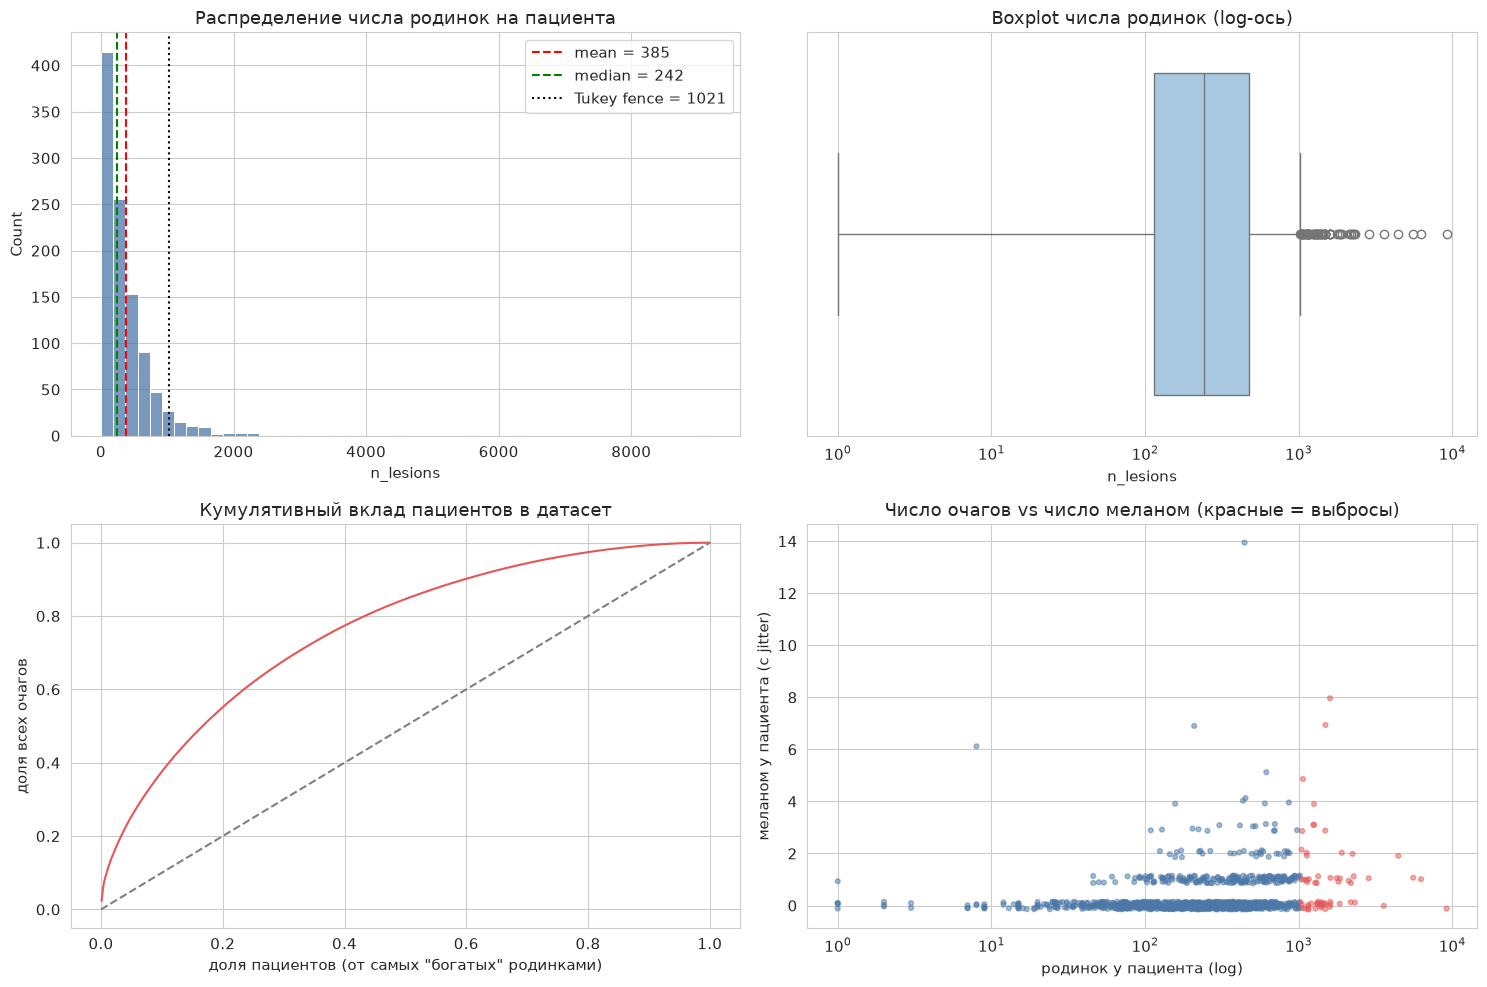

In [12]:
# 2.3 Визуализация структуры пациентов
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(patient['n_lesions'], bins=50, ax=axes[0, 0], color='#4C78A8')
axes[0, 0].axvline(patient.n_lesions.mean(), c='r', ls='--', label=f'mean = {patient.n_lesions.mean():.0f}')
axes[0, 0].axvline(patient.n_lesions.median(), c='g', ls='--', label=f'median = {patient.n_lesions.median():.0f}')
axes[0, 0].axvline(upper_fence, c='k', ls=':', label=f'Tukey fence = {upper_fence:.0f}')
axes[0, 0].set_title('Распределение числа родинок на пациента')
axes[0, 0].legend()

sns.boxplot(x=patient['n_lesions'], ax=axes[0, 1], color='#9ecae9')
axes[0, 1].set_xscale('log')
axes[0, 1].set_title('Boxplot числа родинок (log-ось)')

sorted_cnt = np.sort(patient['n_lesions'].to_numpy())[::-1]
axes[1, 0].plot(np.arange(1, n_patients + 1) / n_patients, np.cumsum(sorted_cnt) / sorted_cnt.sum(), c='#E45756')
axes[1, 0].plot([0, 1], [0, 1], ls='--', c='gray')
axes[1, 0].set_xlabel('доля пациентов (от самых "богатых" родинками)')
axes[1, 0].set_ylabel('доля всех очагов')
axes[1, 0].set_title('Кумулятивный вклад пациентов в датасет')

jit = patient['n_melanoma'] + RNG.uniform(-0.15, 0.15, n_patients)
axes[1, 1].scatter(patient['n_lesions'], jit, s=12, alpha=0.5, c=np.where(patient['is_outlier'], '#E45756', '#4C78A8'))
axes[1, 1].set_xscale('log')
axes[1, 1].set_xlabel('родинок у пациента (log)')
axes[1, 1].set_ylabel('меланом у пациента (с jitter)')
axes[1, 1].set_title('Число очагов vs число меланом (красные = выбросы)')
plt.tight_layout()
save_fig('02_patients_structure')
plt.show()

In [13]:
# 2.4 Меланомы по пациентам: у кого они есть и связано ли это с "богатостью" родинками
n_mel_patients = int(patient.has_melanoma.sum())
print(f'Пациентов хотя бы с одной меланомой: {n_mel_patients} из {n_patients} ({n_mel_patients / n_patients:.1%})')
print('Распределение числа меланом на пациента (только где >= 1):')
print(patient.loc[patient.has_melanoma, 'n_melanoma'].value_counts().sort_index().to_string())

a = patient.loc[patient.has_melanoma, 'n_lesions']
b = patient.loc[~patient.has_melanoma, 'n_lesions']
u = stats.mannwhitneyu(a, b, alternative='two-sided')
rho, p_rho = stats.spearmanr(patient['n_lesions'], patient['melanoma_rate'])
print(f'\nМедиана очагов: пациенты с меланомой = {a.median():.0f}, без меланомы = {b.median():.0f}  (Mann-Whitney p = {u.pvalue:.2e})')
print(f'Spearman(n_lesions, melanoma_rate) = {rho:.3f}  (p = {p_rho:.2e})')

Пациентов хотя бы с одной меланомой: 259 из 1042 (24.9%)
Распределение числа меланом на пациента (только где >= 1):
n_melanoma
1     193
2      35
3      18
4       6
5       2
6       1
7       2
8       1
14      1

Медиана очагов: пациенты с меланомой = 434, без меланомы = 203  (Mann-Whitney p = 1.90e-23)
Spearman(n_lesions, melanoma_rate) = 0.243  (p = 2.00e-15)


### Выводы по разделу 2

* Датасет — это **~1000 пациентов с сотнями очагов у каждого** (в среднем ≈ 380), а не 400 тыс. независимых наблюдений. Строки внутри пациента сильно скоррелированы (тип кожи, освещение, камера).
* Распределение очагов на пациента имеет **тяжёлый правый хвост**; пациенты-выбросы (за границей Тьюки) вносят непропорционально большую долю строк. При GroupKFold они дают неравные по размеру фолды, а при обучении могут «перетягивать» модель на себя → стоит рассмотреть веса `1 / n_lesions_пациента` или ограничение числа негативов на пациента.
* Меланомы сконцентрированы у ограниченного числа пациентов; у большинства из них одна-две меланомы. Это значит, что **признаки конкретного пациента** (его средний размер/цвет родинок) — важный контекст (раздел 8).

---
## 3. Проверка утечек и пересечений (`patient_id` / `lesion_id`)

Цели:
* проверить пересечение пациентов/изображений train ↔ test (если тестовые метаданные доступны);
* убедиться в отсутствии дубликатов `isic_id` / противоречий `lesion_id` ↔ `patient_id`;
* показать, что обычная `StratifiedKFold` «подмешивает» одних и тех же пациентов в train и valid, и построить корректную `StratifiedGroupKFold` по `patient_id`.

In [14]:
# 3.1 Пересечения train <-> test
train_patients = set(df['patient_id'])
train_ids = set(df['isic_id'])

if TEST_PATH is not None:
    test_df = pd.read_csv(TEST_PATH, low_memory=False)
    test_patients = set(test_df['patient_id'])
    inter = train_patients & test_patients
    print(f'test: {len(test_df):,} строк, {len(test_patients)} пациентов')
    print(f'Пересечение patient_id train ∩ test: {len(inter)}')
    print(f'Пересечение isic_id    train ∩ test: {len(train_ids & set(test_df["isic_id"]))}')
else:
    print('ℹ️ test-metadata.csv недоступен (в соревновании тест скрытый и оценивается на сервере Kaggle).')
    print('   Поэтому пересечение пациентов train/test напрямую проверить нельзя; доступна проверка по sample_submission')
    print('   и внутренняя проверка групп. Правило: считаем, что в тесте ДРУГИЕ пациенты -> валидация обязана быть групповой.')

if SUB_PATH is not None:
    sub = pd.read_csv(SUB_PATH)
    print(f'\nsample_submission: {sub.shape}, пересечение isic_id с train: {len(set(sub["isic_id"]) & train_ids)}')

ℹ️ test-metadata.csv недоступен (в соревновании тест скрытый и оценивается на сервере Kaggle).
   Поэтому пересечение пациентов train/test напрямую проверить нельзя; доступна проверка по sample_submission
   и внутренняя проверка групп. Правило: считаем, что в тесте ДРУГИЕ пациенты -> валидация обязана быть групповой.

sample_submission: (3, 2), пересечение isic_id с train: 0


In [15]:
# 3.2 Внутренняя целостность идентификаторов
print('Дубликатов isic_id в train:', df['isic_id'].duplicated().sum())

les = df.dropna(subset=['lesion_id'])
les_patients = les.groupby('lesion_id')['patient_id'].nunique()
les_rows = les.groupby('lesion_id').size()
print(f'\nlesion_id заполнен у {len(les):,} строк ({len(les) / n_total:.2%}); уникальных lesion_id: {les["lesion_id"].nunique():,}')
print(f'lesion_id, привязанных к >1 пациенту: {(les_patients > 1).sum()}')
print(f'lesion_id с >1 снимком (повторные съёмки одного очага): {(les_rows > 1).sum()}')

has_lesion = df['lesion_id'].notna()
print('\nДоля строк с заполненным lesion_id в разрезе target (потенциальная утечка!):')
print(df.groupby(TARGET)['lesion_id'].apply(lambda s: s.notna().mean()).rename('lesion_id_not_null_rate').to_frame())

pat_per_attr = df.groupby('patient_id')['attribution'].nunique()
print(f'\nПациентов, чьи снимки пришли из >1 источника (attribution): {(pat_per_attr > 1).sum()}')
attr = (df.groupby('attribution')
          .agg(rows=('isic_id', 'size'), patients=('patient_id', 'nunique'), melanomas=(TARGET, 'sum')))
attr['per_mille'] = 1000 * attr['melanomas'] / attr['rows']
attr.sort_values('rows', ascending=False)

Дубликатов isic_id в train: 0

lesion_id заполнен у 22,058 строк (5.50%); уникальных lesion_id: 22,058
lesion_id, привязанных к >1 пациенту: 0
lesion_id с >1 снимком (повторные съёмки одного очага): 0

Доля строк с заполненным lesion_id в разрезе target (потенциальная утечка!):
        lesion_id_not_null_rate
target                         
0                        0.0541
1                        1.0000

Пациентов, чьи снимки пришли из >1 источника (attribution): 0


,rows,patients,melanomas,per_mille
attribution,,,,
Memorial Sloan Kettering Cancer Center,129068,398,174,1.3481
"Department of Dermatology, Hospital Clínic de Barcelona",105724,163,72,0.6810
University Hospital of Basel,65218,230,13,0.1993
"Frazer Institute, The University of Queensland, Dermatology Research Centre",51768,176,81,1.5647
ACEMID MIA,28665,44,33,1.1512
"ViDIR Group, Department of Dermatology, Medical University of Vienna",12640,15,14,1.1076
"Department of Dermatology, University of Athens, Andreas Syggros Hospital of Skin and Venereal Diseases, Alexander Stratigos, Konstantinos Liopyris",7976,16,6,0.7523


,shared_patients_mean,pos_valid_min,pos_valid_max,n_valid_min,n_valid_max
scheme,,,,,
GroupKFold,0.0000,55,97,80211,80214
StratifiedGroupKFold,0.0000,77,83,80210,80216
StratifiedKFold (по строкам),"1,031.8000",78,79,80211,80212


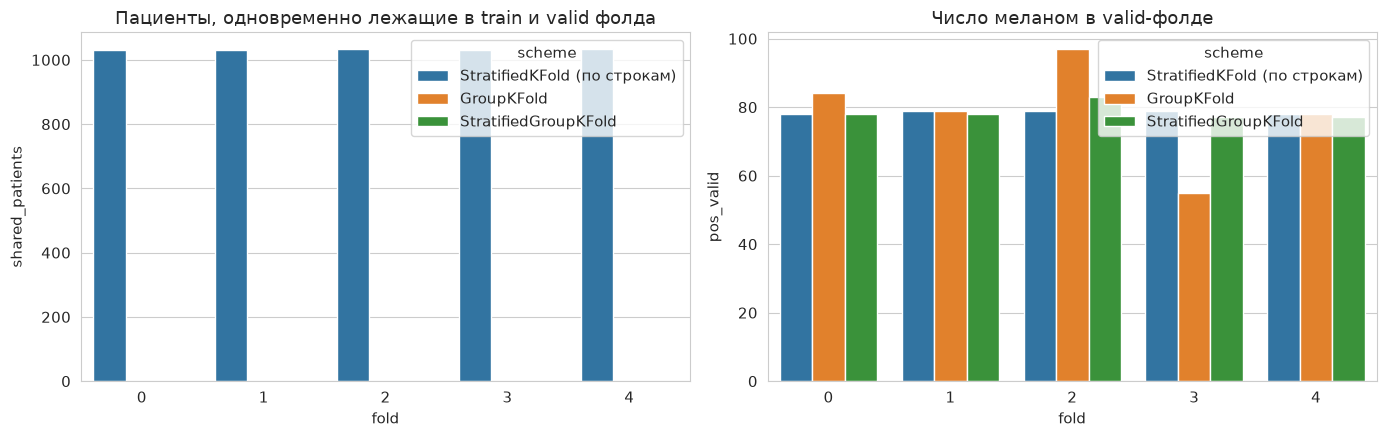

💾 Сохранено: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/csv_outputs/folds_stratified_group_kfold.csv


In [16]:
# 3.3 Почему нужна групповая CV: сравнение схем разбиения
N_SPLITS = 5


def fold_report(splitter, name):
    rows = []
    folds = np.full(n_total, -1)
    for k, (tr, va) in enumerate(splitter.split(df, y, df['patient_id'])):
        pid_tr = set(df['patient_id'].iloc[tr])
        pid_va = set(df['patient_id'].iloc[va])
        rows.append({'scheme': name, 'fold': k, 'n_valid': len(va), 'pos_valid': int(y[va].sum()),
                     'patients_valid': len(pid_va), 'shared_patients': len(pid_tr & pid_va)})
        folds[va] = k
    return pd.DataFrame(rows), folds


rep_skf, _ = fold_report(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED), 'StratifiedKFold (по строкам)')
rep_gkf, _ = fold_report(GroupKFold(N_SPLITS), 'GroupKFold')
rep_sgkf, fold_sgkf = fold_report(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED), 'StratifiedGroupKFold')
fold_tables = pd.concat([rep_skf, rep_gkf, rep_sgkf], ignore_index=True)

display(fold_tables.groupby('scheme')
        .agg(shared_patients_mean=('shared_patients', 'mean'),
             pos_valid_min=('pos_valid', 'min'), pos_valid_max=('pos_valid', 'max'),
             n_valid_min=('n_valid', 'min'), n_valid_max=('n_valid', 'max')))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=fold_tables, x='fold', y='shared_patients', hue='scheme', ax=axes[0])
axes[0].set_title('Пациенты, одновременно лежащие в train и valid фолда')
sns.barplot(data=fold_tables, x='fold', y='pos_valid', hue='scheme', ax=axes[1])
axes[1].set_title('Число меланом в valid-фолде')
plt.tight_layout()
save_fig('03_cv_schemes')
plt.show()

# сохраняем рекомендуемое разбиение
folds_df = pd.DataFrame({'isic_id': df['isic_id'], 'patient_id': df['patient_id'], TARGET: y, 'fold': fold_sgkf})
folds_df.to_csv(CSV_DIR / 'folds_stratified_group_kfold.csv', index=False)
print('💾 Сохранено:', CSV_DIR / 'folds_stratified_group_kfold.csv')

In [17]:
# 3.4 (Опционально) Демонстрация эффекта утечки: одна и та же модель, две схемы CV
# Берём все меланомы + 60k случайных негативов (для скорости) и признаки NUM_FEATURES.
# 3D-координаты, возраст и прочие "отпечатки" пациента позволяют модели узнавать пациента при row-wise CV.
if RUN_LEAK_DEMO:
    neg_idx = RNG.choice(np.flatnonzero(y == 0), 60_000, replace=False)
    sdf = df.iloc[np.r_[np.flatnonzero(y == 1), neg_idx]].reset_index(drop=True)
    Xs, ys, gs = sdf[NUM_FEATURES], sdf[TARGET].to_numpy(), sdf['patient_id']

    def cv_scores(splitter):
        oof = np.zeros(len(sdf))
        for tr, va in splitter.split(Xs, ys, gs):
            model = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15, random_state=SEED)
            model.fit(Xs.iloc[tr], ys[tr])
            oof[va] = model.predict_proba(Xs.iloc[va])[:, 1]
        return {'pAUC': comp_pauc(ys, oof), 'ROC_AUC': roc_auc_score(ys, oof)}

    cv_cmp = pd.DataFrame({
        'StratifiedKFold (строки, УТЕЧКА)': cv_scores(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)),
        'StratifiedGroupKFold (пациенты)': cv_scores(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED)),
    }).T
    display(cv_cmp)
else:
    print('RUN_LEAK_DEMO = False — демонстрация пропущена')

,pAUC,ROC_AUC
"StratifiedKFold (строки, УТЕЧКА)",0.1426,0.9246
StratifiedGroupKFold (пациенты),0.1404,0.9202


### Выводы по разделу 3

* Дубликатов `isic_id` нет; `lesion_id` заполнен лишь у малой части строк (~5 %) и фактически уникален → **использовать `lesion_id` как ключ группировки нельзя, группировать нужно по `patient_id`**.
* Пересечение train/test напрямую проверить нельзя (тест скрыт), но по условиям соревнования в тесте другие пациенты, поэтому единственная честная схема — **`StratifiedGroupKFold` по `patient_id`** (сохранена в `csv_outputs/folds_stratified_group_kfold.csv`).
* Обычная `StratifiedKFold` помещает практически всех пациентов одновременно в train и valid → модель «запоминает» пациента (координаты `tbp_lv_x/y/z`, возраст, цвет кожи) и метрика завышена (см. демонстрацию 3.4).
* Обычная `GroupKFold` корректна по группам, но не стратифицирована: число меланом по фолдам сильно гуляет, что для 393 позитивов критично.
* `lesion_id` заполнен непропорционально часто у меланом (см. 3.2) → это маркер процесса сбора данных (биопсия/наблюдение), **утечка**; его и `iddx_*`, `mel_*` в признаки включать нельзя.
* Колонка `attribution` показывает источники данных (клиники). Распределение меланом по источникам неоднородно → возможен domain shift между train и скрытым тестом.

---
## 4. Анализ клинических признаков

`age_approx`, `sex`, `anatom_site_general` в разрезе `target == 0` и `target == 1`. Для каждого признака: распределение внутри классов, **частота меланом внутри категории** (‰, промилле) и статистический тест.

Возраст: benign медиана=60, mean=58.0 | melanoma медиана=60, mean=61.4
Mann-Whitney p = 1.20e-06;  AUC возраста (P(age_mel > age_benign)) = 0.571


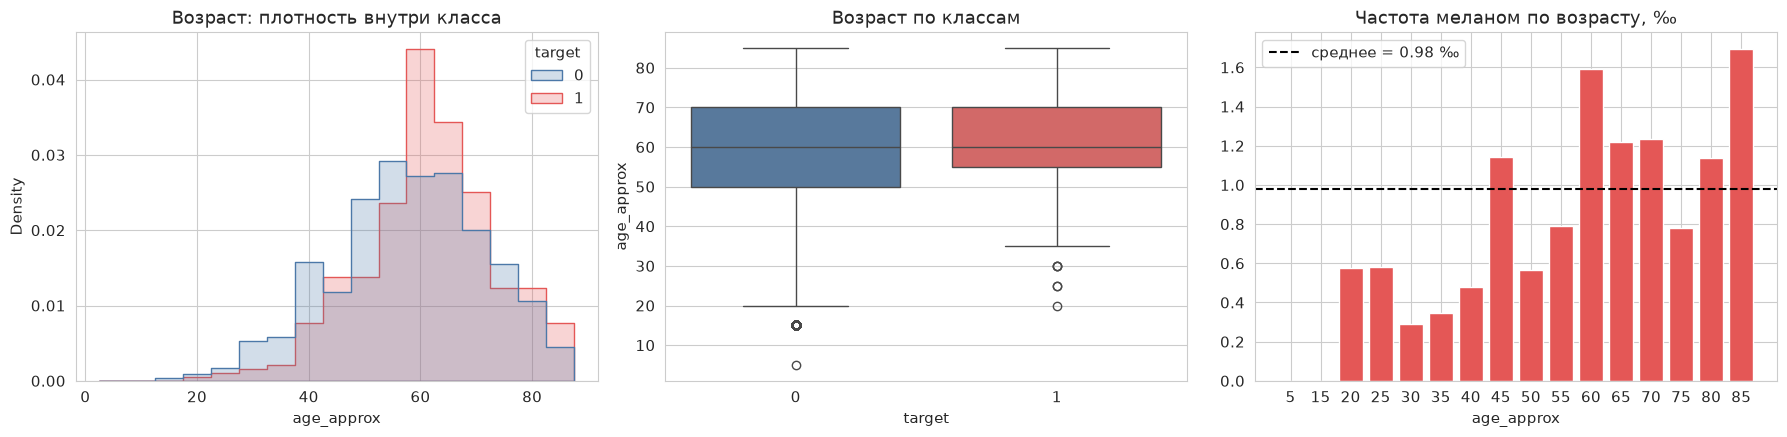

,rows,melanomas,rate,per_mille
age_approx,,,,
5,1,0,0.0000,0.0000
15,644,0,0.0000,0.0000
20,1742,1,0.0006,0.5741
25,3433,2,0.0006,0.5826
30,10400,3,0.0003,0.2885
35,11543,4,0.0003,0.3465
40,31297,15,0.0005,0.4793
45,23580,27,0.0011,1.1450
50,47924,27,0.0006,0.5634


In [18]:
# 4.1 Возраст
age0 = df.loc[df[TARGET] == 0, 'age_approx'].dropna()
age1 = df.loc[df[TARGET] == 1, 'age_approx'].dropna()
mw = stats.mannwhitneyu(age1, age0, alternative='two-sided')
print(f'Возраст: benign медиана={age0.median():.0f}, mean={age0.mean():.1f} | melanoma медиана={age1.median():.0f}, mean={age1.mean():.1f}')
print(f'Mann-Whitney p = {mw.pvalue:.2e};  AUC возраста (P(age_mel > age_benign)) = {mw.statistic / (len(age1) * len(age0)):.3f}')

age_prev = df.groupby('age_approx')[TARGET].agg(rows='size', melanomas='sum', rate='mean')
age_prev['per_mille'] = 1000 * age_prev['rate']
age_prev.index = age_prev.index.astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(data=df, x='age_approx', hue=TARGET, stat='density', common_norm=False, bins=np.arange(2.5, 92.5, 5),
             element='step', palette=PAL, ax=axes[0])
axes[0].set_title('Возраст: плотность внутри класса')
sns.boxplot(data=df, x=TARGET, y='age_approx', hue=TARGET, palette=PAL, legend=False, ax=axes[1])
axes[1].set_title('Возраст по классам')
axes[2].bar(age_prev.index.astype(str), age_prev['per_mille'], color='#E45756')
axes[2].axhline(1000 * PREVALENCE, ls='--', c='k', label=f'среднее = {1000 * PREVALENCE:.2f} ‰')
axes[2].set_title('Частота меланом по возрасту, ‰')
axes[2].set_xlabel('age_approx')
axes[2].legend()
plt.tight_layout()
save_fig('04_age')
plt.show()
age_prev

[sex] chi2 p-value = 3.39e-01, Cramér V = 0.002


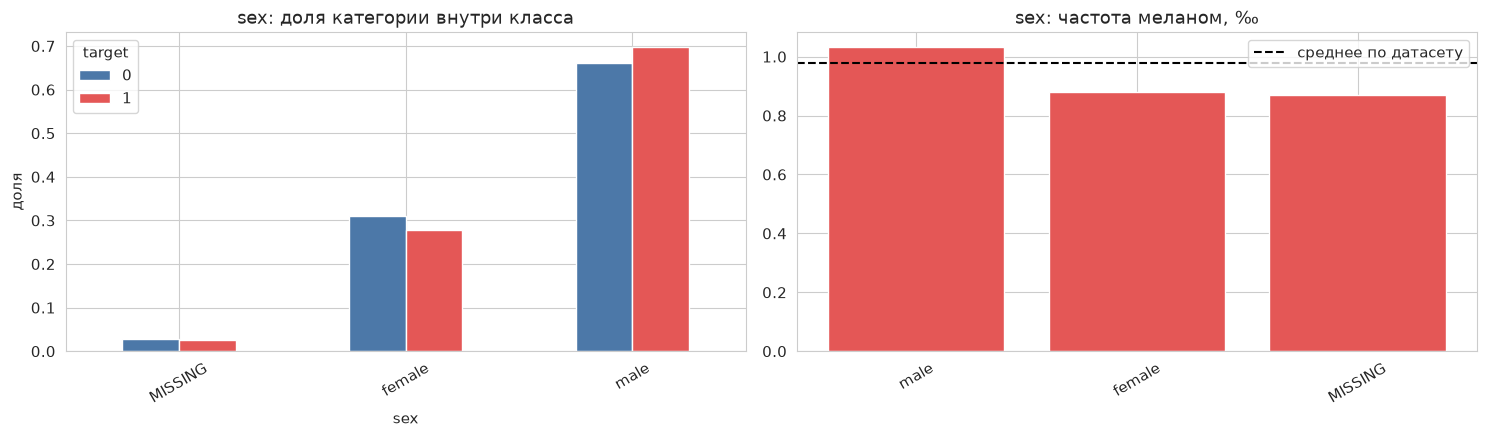

,rows,melanomas,per_mille,lift_vs_overall
sex,,,,
male,265546,274,1.0318,1.0530
female,123996,109,0.8791,0.8971
MISSING,11517,10,0.8683,0.8861


[anatom_site_general] chi2 p-value = 5.24e-82, Cramér V = 0.031


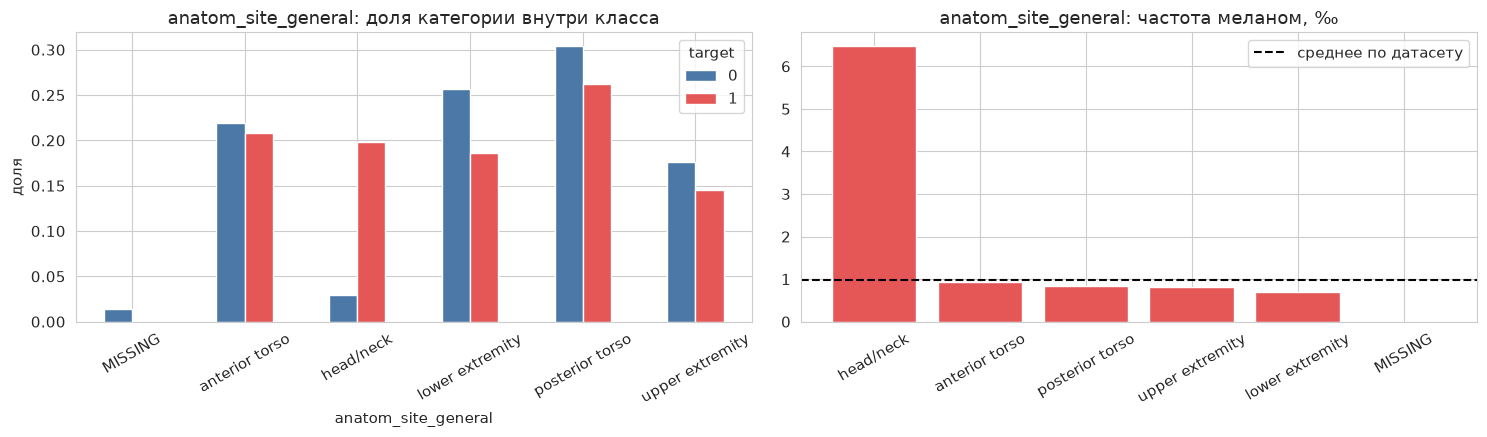

,rows,melanomas,per_mille,lift_vs_overall
anatom_site_general,,,,
head/neck,12046,78,6.4752,6.6080
anterior torso,87770,82,0.9343,0.9534
posterior torso,121902,103,0.8449,0.8623
upper extremity,70557,57,0.8079,0.8244
lower extremity,103028,73,0.7085,0.7231
MISSING,5756,0,0.0000,0.0000


In [19]:
# 4.2 Категориальные признаки: sex и anatom_site_general (пропуски выделяем в отдельную категорию MISSING)
def categorical_report(col):
    s = df[col].astype('object').fillna('MISSING')
    tab = pd.crosstab(s, df[TARGET])
    share_in_class = tab / tab.sum()                        # распределение категорий внутри класса
    prev = pd.DataFrame({'rows': tab.sum(axis=1), 'melanomas': tab[1]})
    prev['per_mille'] = 1000 * prev['melanomas'] / prev['rows']
    prev['lift_vs_overall'] = prev['per_mille'] / (1000 * PREVALENCE)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    cramers_v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    return share_in_class, prev.sort_values('per_mille', ascending=False), p, cramers_v


def plot_categorical(col, fname):
    share, prev, p, v = categorical_report(col)
    print(f'[{col}] chi2 p-value = {p:.2e}, Cramér V = {v:.3f}')
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    share.plot(kind='bar', ax=axes[0], color=[PAL[0], PAL[1]])
    axes[0].set_title(f'{col}: доля категории внутри класса')
    axes[0].set_ylabel('доля')
    axes[0].tick_params(axis='x', rotation=30)
    axes[1].bar(prev.index, prev['per_mille'], color='#E45756')
    axes[1].axhline(1000 * PREVALENCE, ls='--', c='k', label='среднее по датасету')
    axes[1].set_title(f'{col}: частота меланом, ‰')
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].legend()
    plt.tight_layout()
    save_fig(fname)
    plt.show()
    display(prev)


plot_categorical('sex', '04_sex')
plot_categorical('anatom_site_general', '04_anatom_site')

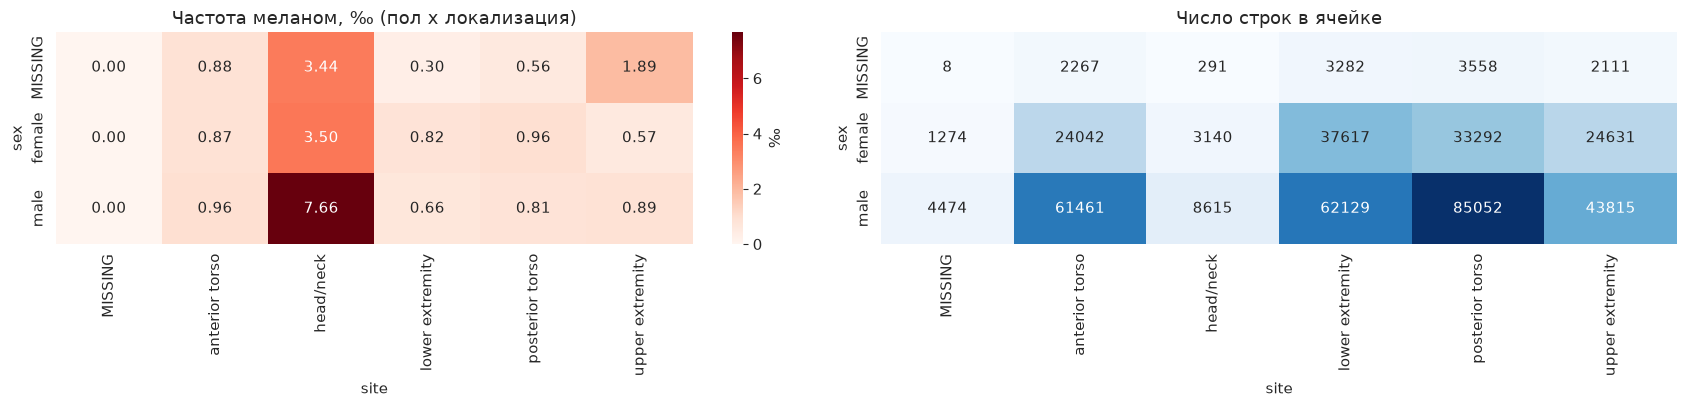

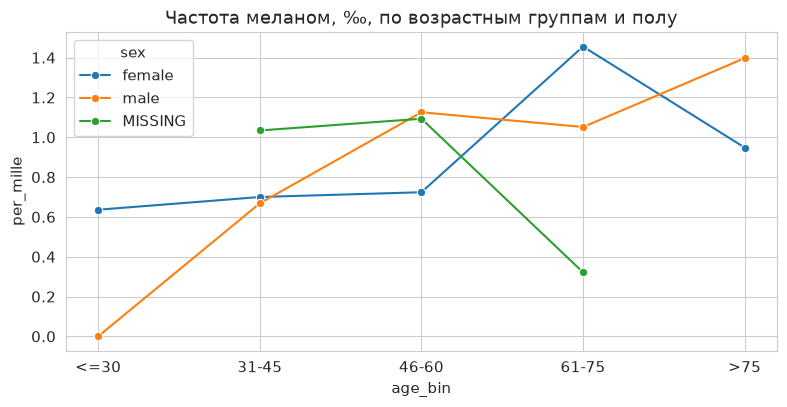

In [20]:
# 4.3 Взаимодействие демографии: пол x локализация и возраст x пол
tmp = df.assign(sex=df['sex'].astype('object').fillna('MISSING'),
                site=df['anatom_site_general'].astype('object').fillna('MISSING'))
heat = tmp.pivot_table(index='sex', columns='site', values=TARGET, aggfunc='mean') * 1000
cnt = tmp.pivot_table(index='sex', columns='site', values=TARGET, aggfunc='size')

fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='Reds', ax=axes[0], cbar_kws={'label': '‰'})
axes[0].set_title('Частота меланом, ‰ (пол x локализация)')
sns.heatmap(cnt, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title('Число строк в ячейке')
plt.tight_layout()
save_fig('04_sex_site_heatmap')
plt.show()

age_bins = pd.cut(df['age_approx'], [0, 30, 45, 60, 75, 100], labels=['<=30', '31-45', '46-60', '61-75', '>75'])
by_age_sex = (df.assign(age_bin=age_bins, sex=df['sex'].astype('object').fillna('MISSING'))
                .groupby(['age_bin', 'sex'], observed=True)[TARGET].agg(['size', 'mean']).reset_index())
by_age_sex['per_mille'] = 1000 * by_age_sex['mean']
by_age_sex = by_age_sex[by_age_sex['size'] >= 500]            # отсекаем слишком малые группы
plt.figure(figsize=(8, 4.2))
sns.lineplot(data=by_age_sex, x='age_bin', y='per_mille', hue='sex', marker='o')
plt.title('Частота меланом, ‰, по возрастным группам и полу')
plt.tight_layout()
save_fig('04_age_sex')
plt.show()

### Выводы по разделу 4

* **Возраст** — самый заметный клинический фактор: меланомы в среднем у более старших пациентов, а частота меланом растёт с возрастом (график ‰ по возрасту). Признак полезен, но по силе сопоставим с «слабым» (см. AUC в 4.1).
* **Пол**: у мужчин и женщин частота меланом отличается (chi², Cramér V — в выводе ячейки); эффект небольшой по силе, но статистически значим из-за размера выборки. Отдельная категория `MISSING` ведёт себя иначе, чем основные значения (подробнее — раздел 6).
* **Локализация**: частота меланом различается между зонами тела (туловище vs конечности vs голова/шея); `lift_vs_overall` показывает, во сколько раз зона «опаснее» среднего.
* Демографические эффекты умеренные, поэтому одних клинических признаков недостаточно: основной вклад должны дать TBP-признаки и контекст пациента.
* Поскольку возраст/пол — признаки **пациента**, а не очага, GBDT может использовать их как «идентификатор пациента» → ещё один довод за групповую CV.

---
## 5. Геометрические и цветовые признаки (3D-TBP)

Изучаем оцифрованные параметры родинок: диаметр `clin_size_long_diam_mm`, периметр, площадь, асимметрия, цветовые каналы `tbp_lv_*`.
Для каждого признака считаем:
* медианы по классам;
* **ROC AUC** и **pAUC** одного признака (с автоматическим выбором направления) — реальная мера разделяющей способности;
* p-value теста Манна–Уитни.

In [21]:
# 5.1 Таблица разделяющей способности всех числовых признаков
def feature_group(f):
    if f == 'age_approx':
        return 'clinical'
    if f in GEOM_COLS:
        return 'geometry'
    if f in COLOR_COLS:
        return 'color'
    return 'position/other'


uni_rows = []
for f in NUM_FEATURES:
    x = df[f].to_numpy(dtype=float)
    a, sign, pa = univariate_scores(y, x)
    x0, x1 = x[y == 0], x[y == 1]
    p = stats.mannwhitneyu(x1[~np.isnan(x1)], x0[~np.isnan(x0)], alternative='two-sided').pvalue
    uni_rows.append({'feature': f, 'group': feature_group(f),
                     'median_benign': np.nanmedian(x0), 'median_melanoma': np.nanmedian(x1),
                     'direction': '↑ меланома' if sign > 0 else '↓ меланома',
                     'auc': a, 'pAUC': pa, 'pAUC_norm': pa / 0.2, 'mw_p': p})
df_uni = pd.DataFrame(uni_rows).sort_values('pAUC', ascending=False).reset_index(drop=True)
df_uni.to_csv(CSV_DIR / 'isic2024_univariate_separability.csv', index=False)
print('💾 Сохранено:', CSV_DIR / 'isic2024_univariate_separability.csv')
df_uni

💾 Сохранено: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/csv_outputs/isic2024_univariate_separability.csv


,feature,group,median_benign,median_melanoma,direction,auc,pAUC,pAUC_norm,mw_p
0,tbp_lv_H,color,55.0401,47.2779,↓ меланома,0.8053,0.0772,0.3862,0.0000
1,tbp_lv_deltaB,color,1.5957,-0.6499,↓ меланома,0.7541,0.0704,0.3522,0.0000
2,tbp_lv_B,color,28.1750,24.0437,↓ меланома,0.7120,0.0562,0.2812,0.0000
3,tbp_lv_Hext,color,61.1127,55.3854,↓ меланома,0.7195,0.0444,0.2221,0.0000
4,tbp_lv_stdLExt,color,2.1495,2.5346,↑ меланома,0.6622,0.0399,0.1997,0.0000
5,tbp_lv_Bext,color,26.7032,25.0776,↓ меланома,0.6150,0.0378,0.1890,0.0000
6,tbp_lv_nevi_confidence,position/other,14.4517,0.4897,↓ меланома,0.6457,0.0366,0.1832,0.0000
7,tbp_lv_Aext,color,14.7123,16.8771,↑ меланома,0.6586,0.0354,0.1772,0.0000
8,age_approx,clinical,60.0000,60.0000,↑ меланома,0.5706,0.0351,0.1753,0.0000
9,tbp_lv_x,position/other,-5.7248,-22.8993,↓ меланома,0.5243,0.0306,0.1529,0.0958


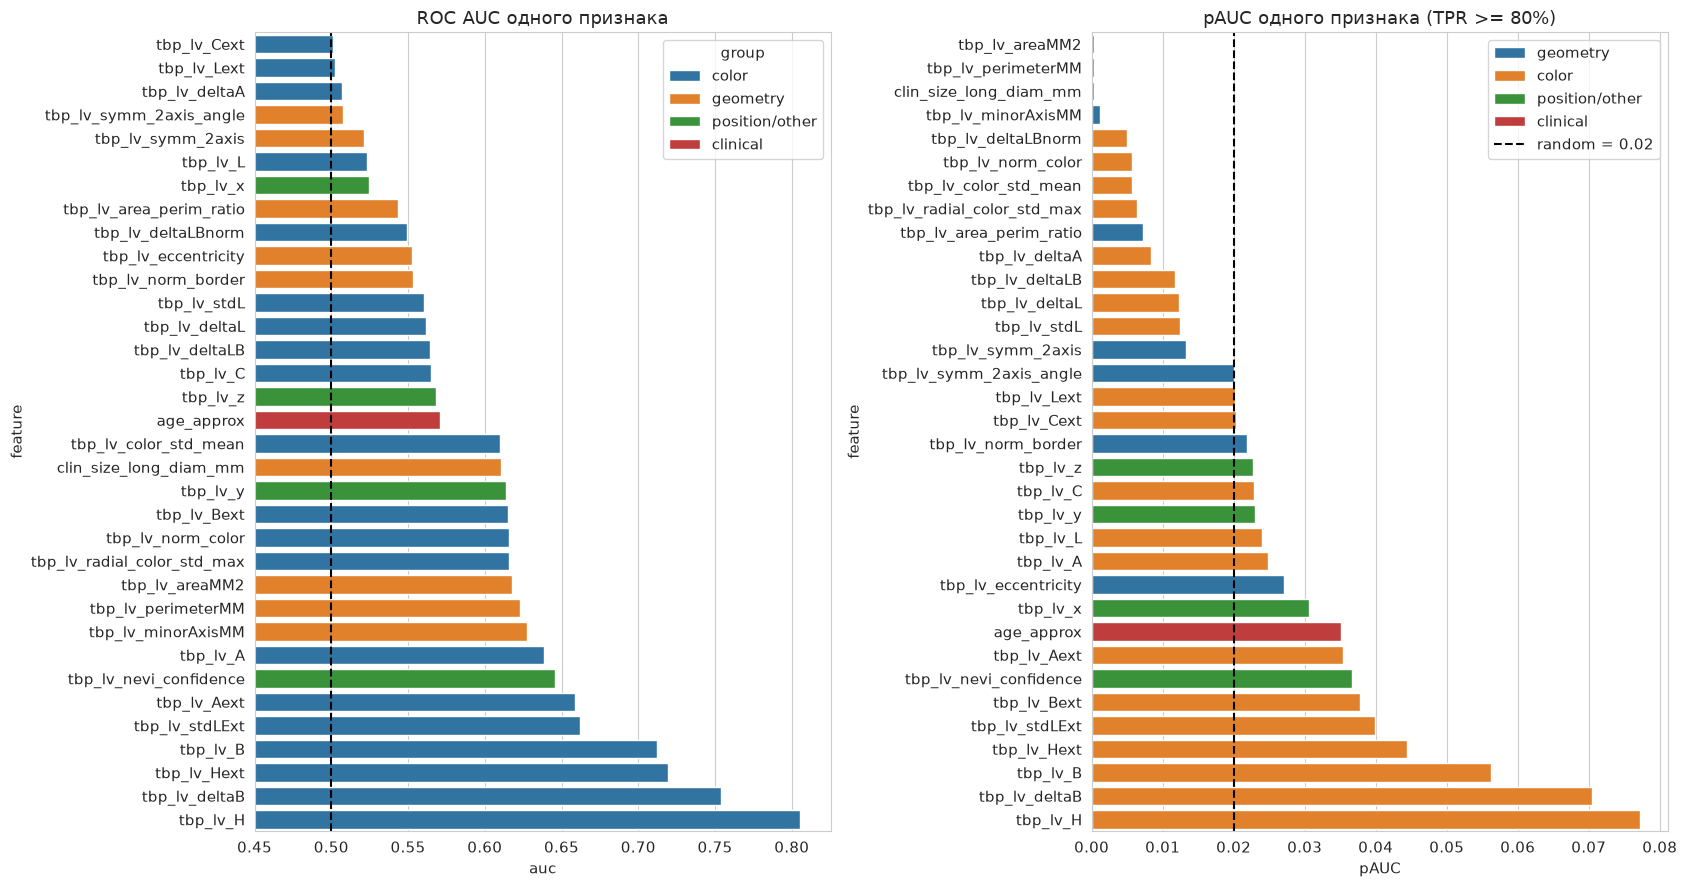

In [22]:
# 5.2 Ранжирование признаков по разделяющей способности
fig, axes = plt.subplots(1, 2, figsize=(17, 9))
order = df_uni.sort_values('auc', ascending=True)
sns.barplot(data=order, y='feature', x='auc', hue='group', dodge=False, ax=axes[0])
axes[0].axvline(0.5, c='k', ls='--')
axes[0].set_xlim(0.45, max(0.8, order['auc'].max() + 0.02))
axes[0].set_title('ROC AUC одного признака')
order2 = df_uni.sort_values('pAUC', ascending=True)
sns.barplot(data=order2, y='feature', x='pAUC', hue='group', dodge=False, ax=axes[1])
axes[1].axvline(0.02, c='k', ls='--', label='random = 0.02')
axes[1].set_title('pAUC одного признака (TPR >= 80%)')
axes[1].legend()
plt.tight_layout()
save_fig('05_univariate_ranking')
plt.show()

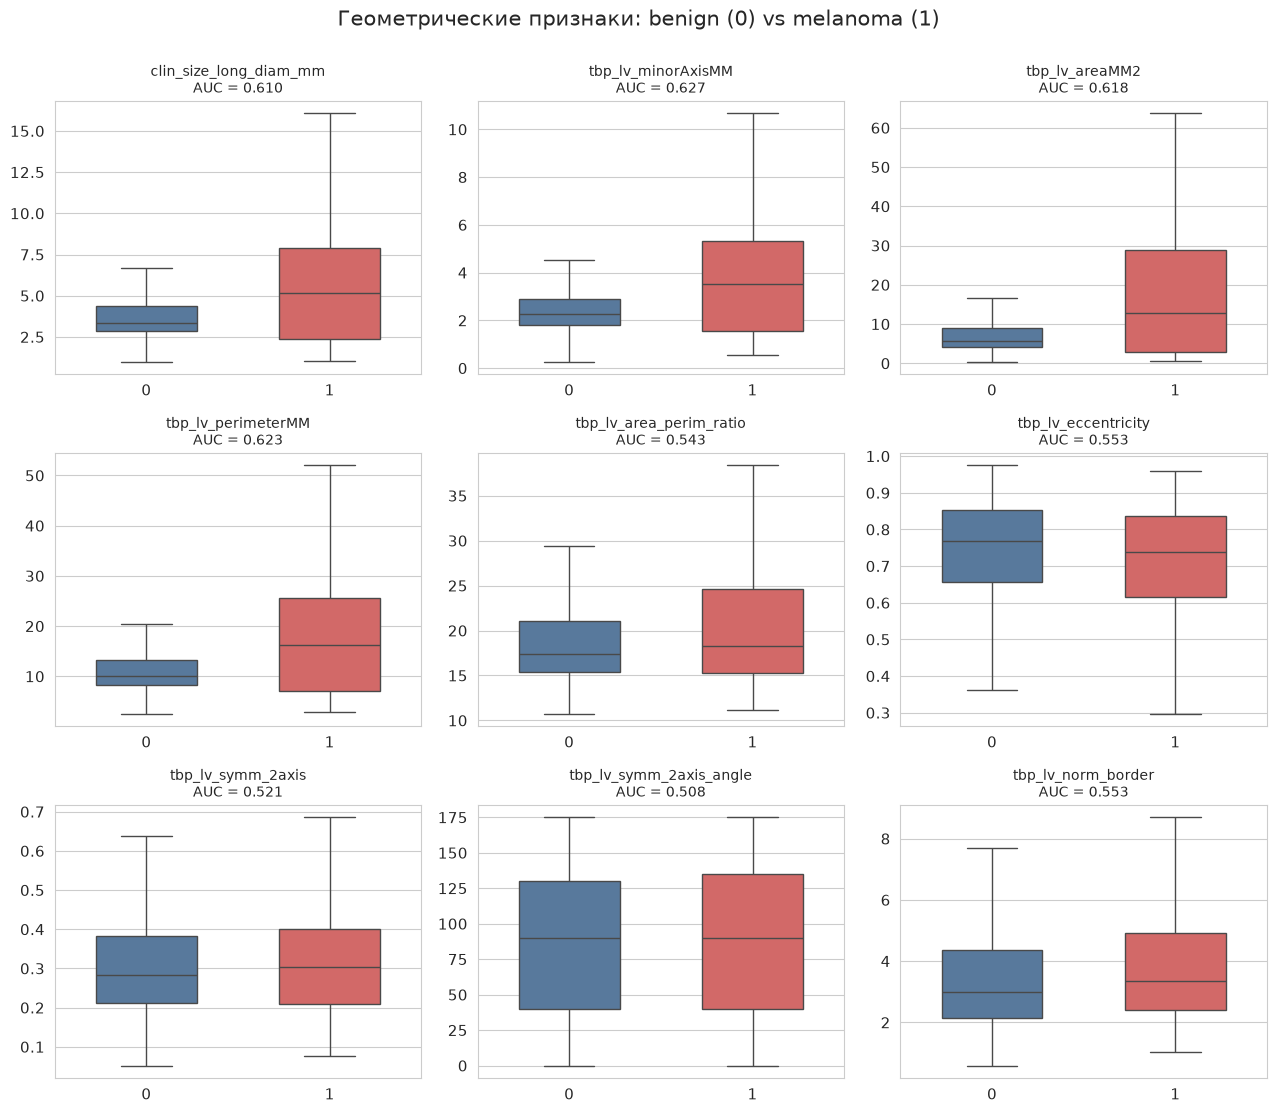

In [23]:
# 5.3 BoxPlot'ы: геометрия очага (сверху — по классам, без выбросов, в заголовке — AUC признака)
auc_map = df_uni.set_index('feature')['auc']


def boxplot_grid(features, ncols, title, fname):
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.7 * nrows))
    axes = np.array(axes).ravel()
    for ax, f in zip(axes, features):
        sns.boxplot(data=df, x=TARGET, y=f, hue=TARGET, palette=PAL, showfliers=False, legend=False, width=0.55, ax=ax)
        ax.set_title(f'{f}\nAUC = {auc_map[f]:.3f}', fontsize=10)
        ax.set_xlabel('')
        ax.set_ylabel('')
    for ax in axes[len(features):]:
        ax.axis('off')
    fig.suptitle(title, y=1.0, fontsize=15)
    plt.tight_layout()
    save_fig(fname)
    plt.show()


boxplot_grid(GEOM_COLS, 3, 'Геометрические признаки: benign (0) vs melanoma (1)', '05_boxplot_geometry')

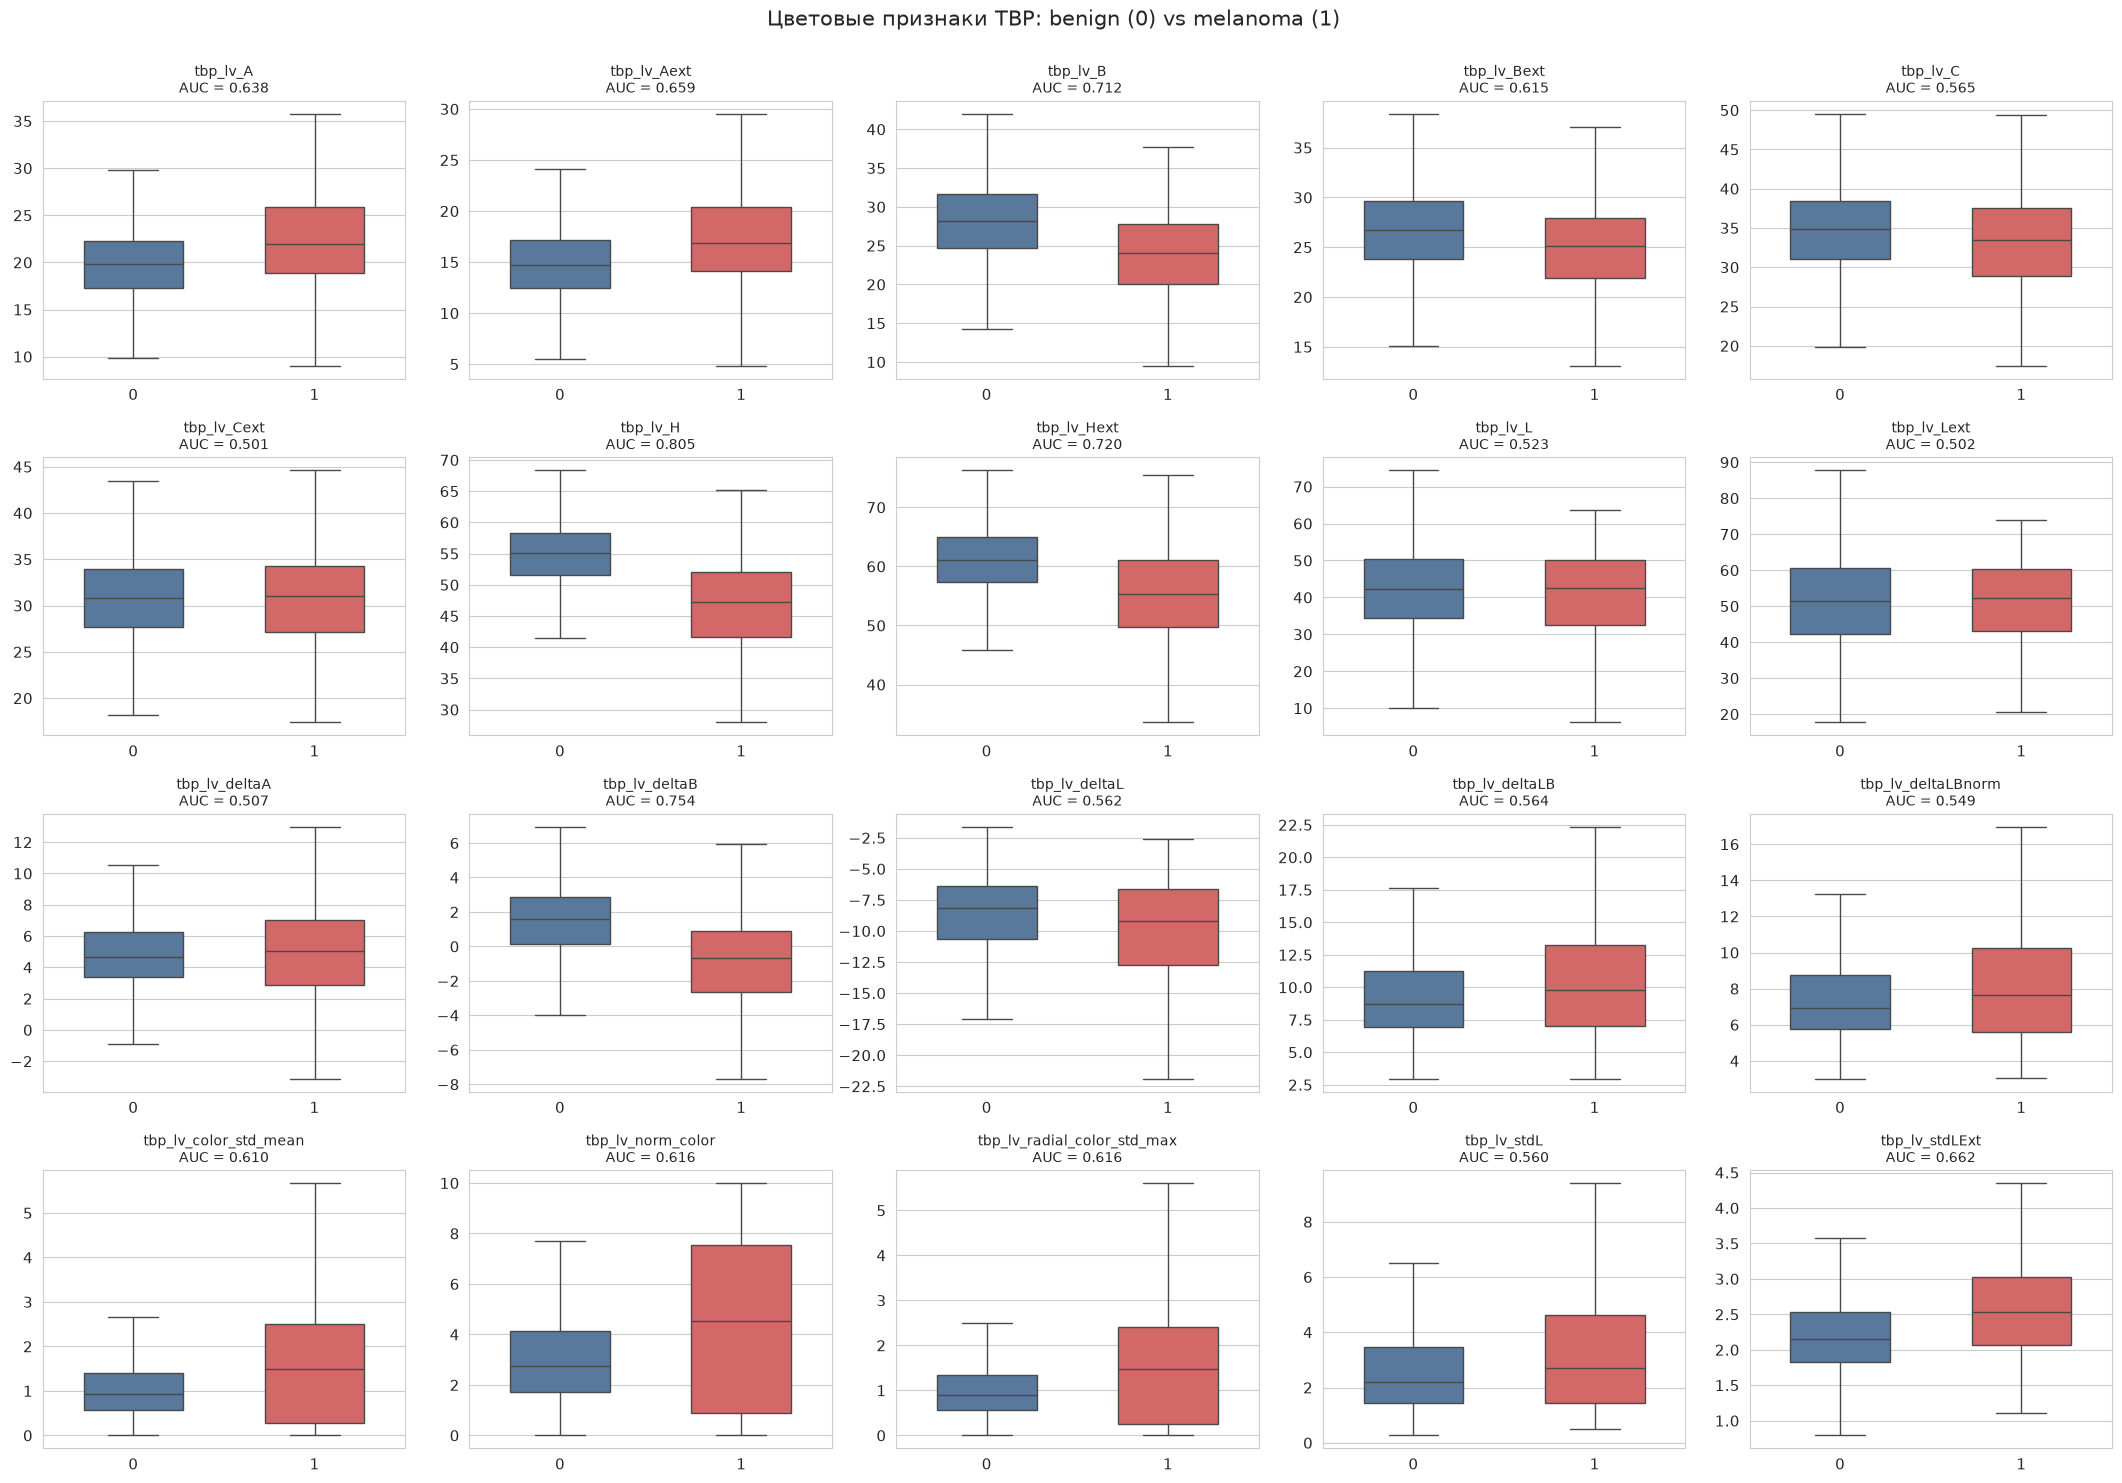

In [24]:
# 5.4 BoxPlot'ы: цветовые каналы tbp_lv_*
boxplot_grid(COLOR_COLS, 5, 'Цветовые признаки TBP: benign (0) vs melanoma (1)', '05_boxplot_color')

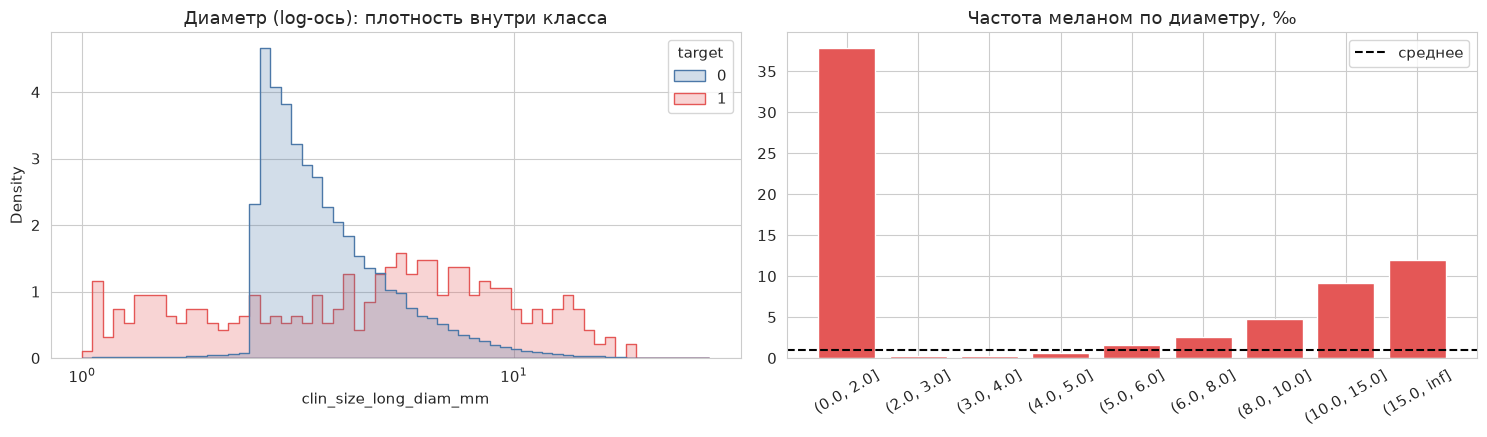

,rows,melanomas,rate,per_mille
clin_size_long_diam_mm,,,,
"(0.0, 2.0]",2113,80,0.0379,37.8609
"(2.0, 3.0]",137030,41,0.0003,0.2992
"(3.0, 4.0]",135554,35,0.0003,0.2582
"(4.0, 5.0]",58570,33,0.0006,0.5634
"(5.0, 6.0]",29220,46,0.0016,1.5743
"(6.0, 8.0]",24389,63,0.0026,2.5831
"(8.0, 10.0]",8286,39,0.0047,4.7067
"(10.0, 15.0]",5144,47,0.0091,9.1369
"(15.0, inf]",753,9,0.0120,11.9522


In [25]:
# 5.5 Диаметр очага: распределение и частота меланом по размерным интервалам
diam = df['clin_size_long_diam_mm']
size_bins = pd.cut(diam, [0, 2, 3, 4, 5, 6, 8, 10, 15, np.inf])
size_prev = (df.groupby(size_bins, observed=True)[TARGET].agg(rows='size', melanomas='sum', rate='mean'))
size_prev['per_mille'] = 1000 * size_prev['rate']

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=df, x='clin_size_long_diam_mm', hue=TARGET, stat='density', common_norm=False, log_scale=True,
             element='step', bins=60, palette=PAL, ax=axes[0])
axes[0].set_title('Диаметр (log-ось): плотность внутри класса')
axes[1].bar(size_prev.index.astype(str), size_prev['per_mille'], color='#E45756')
axes[1].axhline(1000 * PREVALENCE, ls='--', c='k', label='среднее')
axes[1].set_title('Частота меланом по диаметру, ‰')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()
plt.tight_layout()
save_fig('05_diameter')
plt.show()
size_prev

[tbp_lv_location_simple] chi2 p-value = 9.96e-81, Cramér V = 0.031


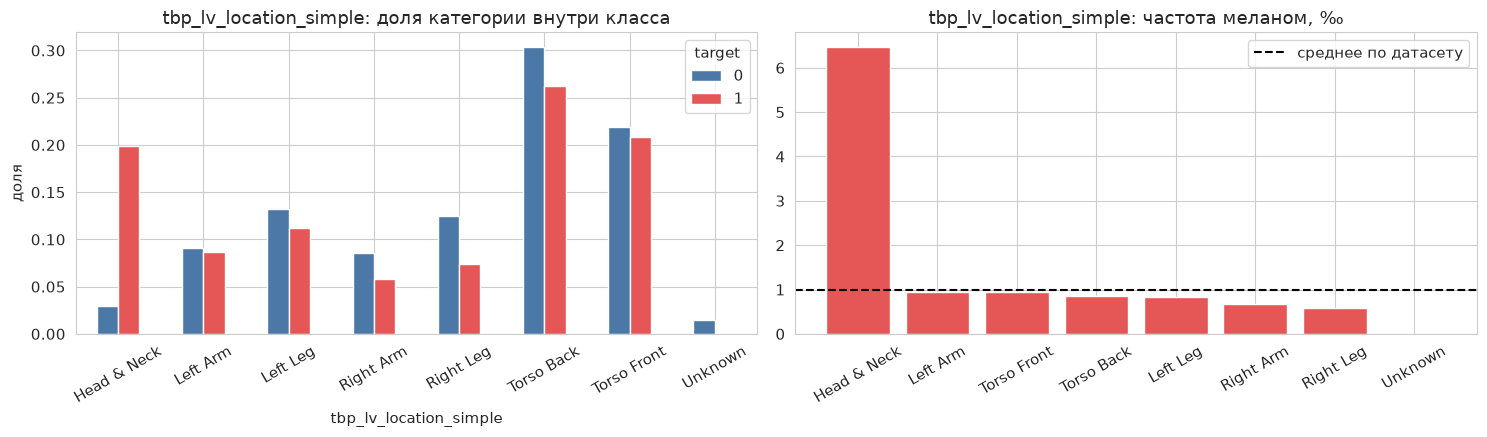

,rows,melanomas,per_mille,lift_vs_overall
tbp_lv_location_simple,,,,
Head & Neck,12046,78,6.4752,6.6080
Left Arm,36348,34,0.9354,0.9546
Torso Front,87770,82,0.9343,0.9534
Torso Back,121902,103,0.8449,0.8623
Left Leg,53075,44,0.8290,0.8460
Right Arm,34209,23,0.6723,0.6861
Right Leg,49953,29,0.5805,0.5925
Unknown,5756,0,0.0000,0.0000


tbp_tile_type: p = 2.96e-20, Cramér V = 0.015


,rows,melanomas,per_mille,lift_vs_overall
tbp_tile_type,,,,
3D: white,115156,196,1.7020,1.7369
3D: XP,285903,197,0.6890,0.7032


In [26]:
# 5.6 Категориальные TBP-признаки: локализация (простая), тип тайла
plot_categorical('tbp_lv_location_simple', '05_location_simple')
_, prev_tile, p_tile, v_tile = categorical_report('tbp_tile_type')
print(f'tbp_tile_type: p = {p_tile:.2e}, Cramér V = {v_tile:.3f}')
prev_tile

### Выводы по разделу 5

* Ни один отдельный признак не даёт «чистого» разделения: boxplot'ы классов сильно перекрываются, а одномерные AUC скромные. Это ожидаемо: меланома — редкий класс, а большинство невусов выглядят «обычно».
* Наиболее информативны, как правило, **размер** (диаметр, площадь, периметр, малая ось), **нерегулярность цвета** (`tbp_lv_deltaLBnorm`, `tbp_lv_color_std_mean`, `tbp_lv_norm_color`, `tbp_lv_radial_color_std_max`), **контраст с окружающей кожей** (`tbp_lv_deltaL/A/B`) и **уверенность «невус»** (`tbp_lv_nevi_confidence`: чем она ниже, тем вероятнее меланома). Точный рейтинг — в таблице 5.1 и на графике 5.2.
* Частота меланом растёт с диаметром (график 5.5): мелкие очаги практически не бывают меланомами, крупные — чаще.
* Распределения тяжёлохвостые → для линейных моделей нужны логарифмы/квантильные преобразования; для GBDT — не критично.
* Единичные признаки слабы, значит выигрыш даст **комбинация признаков** (бустинг) и **контекст пациента** (раздел 8).

---
## 6. Поиск и обработка пропусков (NaN)

Определяем долю пропусков и отвечаем на главный вопрос: **случайны ли пропуски (MCAR/MAR) или связаны со злокачественностью (MNAR / утечка)**.

,n_missing,pct,kind
iddx_5,401058,99.9998,train-only / структурный
mel_mitotic_index,401006,99.9868,train-only / структурный
mel_thick_mm,400996,99.9843,train-only / структурный
iddx_4,400508,99.8626,train-only / структурный
iddx_3,399994,99.7345,train-only / структурный
iddx_2,399991,99.7337,train-only / структурный
lesion_id,379001,94.5001,train-only / структурный
sex,11517,2.8716,клинический
anatom_site_general,5756,1.4352,клинический
age_approx,2798,0.6977,клинический


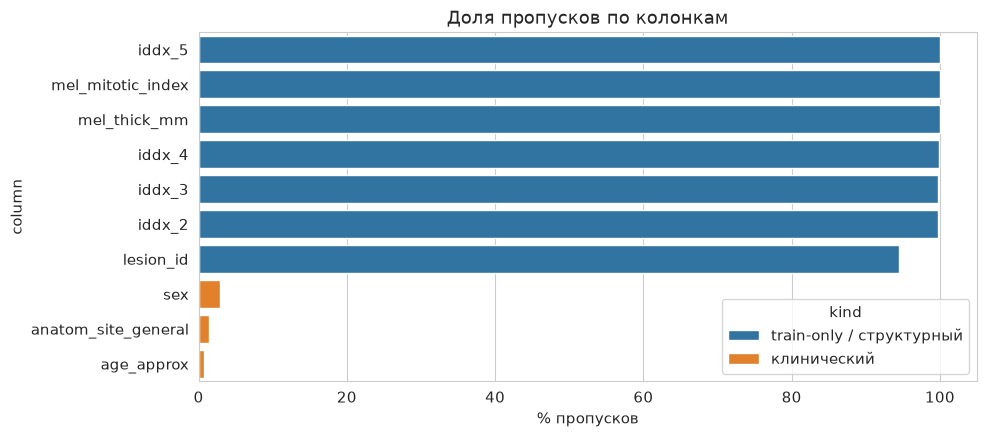

In [27]:
# 6.1 Доля пропусков по колонкам
na = df.isna().sum().to_frame('n_missing')
na['pct'] = 100 * na['n_missing'] / n_total
na = na[na['n_missing'] > 0].sort_values('pct', ascending=False)
na['kind'] = np.where(na.index.isin(LEAK_COLS), 'train-only / структурный', 'клинический')
display(na)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=na.reset_index(names='column'), y='column', x='pct', hue='kind', dodge=False, ax=ax)
ax.set_xlabel('% пропусков')
ax.set_title('Доля пропусков по колонкам')
plt.tight_layout()
save_fig('06_missing_share')
plt.show()

In [28]:
# 6.2 Связь пропуска с target: частота меланом среди строк С пропуском и БЕЗ него + точный тест Фишера
miss_rows = []
for c in na.index:
    miss = df[c].isna().to_numpy()
    tab = pd.crosstab(miss, y).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    odds, p = stats.fisher_exact(tab.values)
    miss_rows.append({'column': c,
                      'miss_rate_benign': miss[y == 0].mean(), 'miss_rate_melanoma': miss[y == 1].mean(),
                      'per_mille_if_missing': 1000 * y[miss].mean(),
                      'per_mille_if_present': 1000 * y[~miss].mean() if (~miss).any() else np.nan,
                      'odds_ratio': odds, 'fisher_p': p})
miss_vs_target = pd.DataFrame(miss_rows)
miss_vs_target['signal'] = np.where(miss_vs_target['fisher_p'] < 0.001, 'ЗАВИСИТ от target', 'нет связи')
miss_vs_target.to_csv(CSV_DIR / 'isic2024_missing_vs_target.csv', index=False)
miss_vs_target

,column,miss_rate_benign,miss_rate_melanoma,per_mille_if_missing,per_mille_if_present,odds_ratio,fisher_p,signal
0,iddx_5,1.0000,1.0000,0.9799,0.0000,inf,1.0000,нет связи
1,mel_mitotic_index,1.0000,0.8651,0.8479,"1,000.0000",0.0000,0.0000,ЗАВИСИТ от target
2,mel_thick_mm,1.0000,0.8397,0.8230,"1,000.0000",0.0000,0.0000,ЗАВИСИТ от target
3,iddx_4,0.9992,0.3842,0.3770,439.2015,0.0005,0.0000,ЗАВИСИТ от target
4,iddx_3,0.9983,0.0000,0.0000,369.0141,0.0000,0.0000,ЗАВИСИТ от target
5,iddx_2,0.9983,0.0000,0.0000,367.9775,0.0000,0.0000,ЗАВИСИТ от target
6,lesion_id,0.9459,0.0000,0.0000,17.8167,0.0000,0.0000,ЗАВИСИТ от target
7,sex,0.0287,0.0254,0.8683,0.9832,0.8830,0.8793,нет связи
8,anatom_site_general,0.0144,0.0000,0.0000,0.9942,0.0000,0.0085,нет связи
9,age_approx,0.0070,0.0076,1.0722,0.9793,1.0950,0.7572,нет связи


In [29]:
# 6.3 Природа пропусков в клинических признаках: на уровне пациента? на уровне источника? можно ли восстановить?
clin_na_cols = ['age_approx', 'sex', 'anatom_site_general']

print('--- Пропуски на уровне пациента ---')
for c in clin_na_cols:
    pm = df[c].isna().groupby(df['patient_id']).mean()
    print(f'{c:22s}: пациентов с пропусками = {(pm > 0).sum():4d}; полностью пропущено у {(pm == 1).sum():4d}; частично у {((pm > 0) & (pm < 1)).sum():4d}')

print('\n--- Доля пропусков по источнику (attribution) ---')
miss_by_attr = df[clin_na_cols].isna().groupby(df['attribution']).mean()
display(miss_by_attr)
for c in clin_na_cols:
    tab = pd.crosstab(df['attribution'], df[c].isna())
    if tab.shape[1] == 2:
        print(f'{c:22s}: chi2 p (пропуск vs источник) = {stats.chi2_contingency(tab)[1]:.2e}')

print('\n--- anatom_site_general = NaN против tbp_lv_location_simple (можно ли восстановить зону?) ---')
display(pd.crosstab(df['tbp_lv_location_simple'], df['anatom_site_general'].isna(), margins=True)
        .rename(columns={False: 'site известен', True: 'site NaN'}))

print('--- Можно ли восстановить sex по другим строкам того же пациента? ---')
sex_nuniq = df.groupby('patient_id')['sex'].nunique()
print('Пациентов с >1 различным значением sex:', int((sex_nuniq > 1).sum()))
recoverable = df['sex'].isna() & df['patient_id'].map(sex_nuniq).gt(0)
print(f'Строк с NaN в sex: {df["sex"].isna().sum():,}; из них восстановимо по тому же пациенту: {int(recoverable.sum()):,}')

--- Пропуски на уровне пациента ---
age_approx            : пациентов с пропусками =   13; полностью пропущено у   13; частично у    0
sex                   : пациентов с пропусками =   33; полностью пропущено у   33; частично у    0
anatom_site_general   : пациентов с пропусками =   35; полностью пропущено у   11; частично у   24

--- Доля пропусков по источнику (attribution) ---


,age_approx,sex,anatom_site_general
attribution,,,
ACEMID MIA,0.0000,0.0000,0.0000
"Department of Dermatology, Hospital Clínic de Barcelona",0.0138,0.0043,0.0016
"Department of Dermatology, University of Athens, Andreas Syggros Hospital of Skin and Venereal Diseases, Alexander Stratigos, Konstantinos Liopyris",0.0000,0.0000,0.0000
"Frazer Institute, The University of Queensland, Dermatology Research Centre",0.0233,0.0448,0.0453
Memorial Sloan Kettering Cancer Center,0.0000,0.0000,0.0089
University Hospital of Basel,0.0020,0.1341,0.0320
"ViDIR Group, Department of Dermatology, Medical University of Vienna",0.0000,0.0000,0.0002


age_approx            : chi2 p (пропуск vs источник) = 0.00e+00
sex                   : chi2 p (пропуск vs источник) = 0.00e+00
anatom_site_general   : chi2 p (пропуск vs источник) = 0.00e+00

--- anatom_site_general = NaN против tbp_lv_location_simple (можно ли восстановить зону?) ---


anatom_site_general,site известен,site NaN,All
tbp_lv_location_simple,,,
Head & Neck,12046,0,12046
Left Arm,36348,0,36348
Left Leg,53075,0,53075
Right Arm,34209,0,34209
Right Leg,49953,0,49953
Torso Back,121902,0,121902
Torso Front,87770,0,87770
Unknown,0,5756,5756
All,395303,5756,401059


--- Можно ли восстановить sex по другим строкам того же пациента? ---
Пациентов с >1 различным значением sex: 0
Строк с NaN в sex: 11,517; из них восстановимо по тому же пациенту: 0


### Выводы по разделу 6

* **Клинические признаки** (`age_approx`, `sex`, `anatom_site_general`) пропущены у 0.7 % – 2.9 % строк — это мало. Пропуски сгруппированы по пациентам/источникам (см. 6.3), т. е. **не полностью случайны (MAR)**: их причина — процесс сбора данных конкретного источника, а не свойства очага.
* По таблице 6.2 видно, имеет ли пропуск связь с меланомой (`per_mille_if_missing` vs `per_mille_if_present`, `fisher_p`). Если связь есть — пропуск лучше сохранять как отдельный сигнал (`isna`-флаг или категория `MISSING`), а не молча импьютить.
* **Структурные пропуски** (`lesion_id`, `iddx_2…5`, `mel_mitotic_index`, `mel_thick_mm`) — это не «пропуски данных», а признак того, что очаг прошёл через биопсию/углублённую диагностику. Их заполненность **напрямую коррелирует с target** (например, `mel_*` заполняются почти исключительно для меланом) → это **утечка**, колонки нужно удалить и не использовать даже через `isna`-флаги.
* Рекомендации: GBDT (LightGBM/XGBoost/CatBoost) обрабатывают NaN нативно; для `sex` можно восстановить значение по другим строкам того же пациента; для `anatom_site_general` — по `tbp_lv_location_simple`; `age_approx` — медиана по пациенту.

---
## 7. Анализ мультиколлинеарности метаданных

Строим корреляционную матрицу (Spearman — устойчива к тяжёлым хвостам), находим линейно зависимые пары (например, площадь ↔ периметр ↔ диаметр), группируем признаки в кластеры и формируем список к удалению **до** подачи в LightGBM/XGBoost.

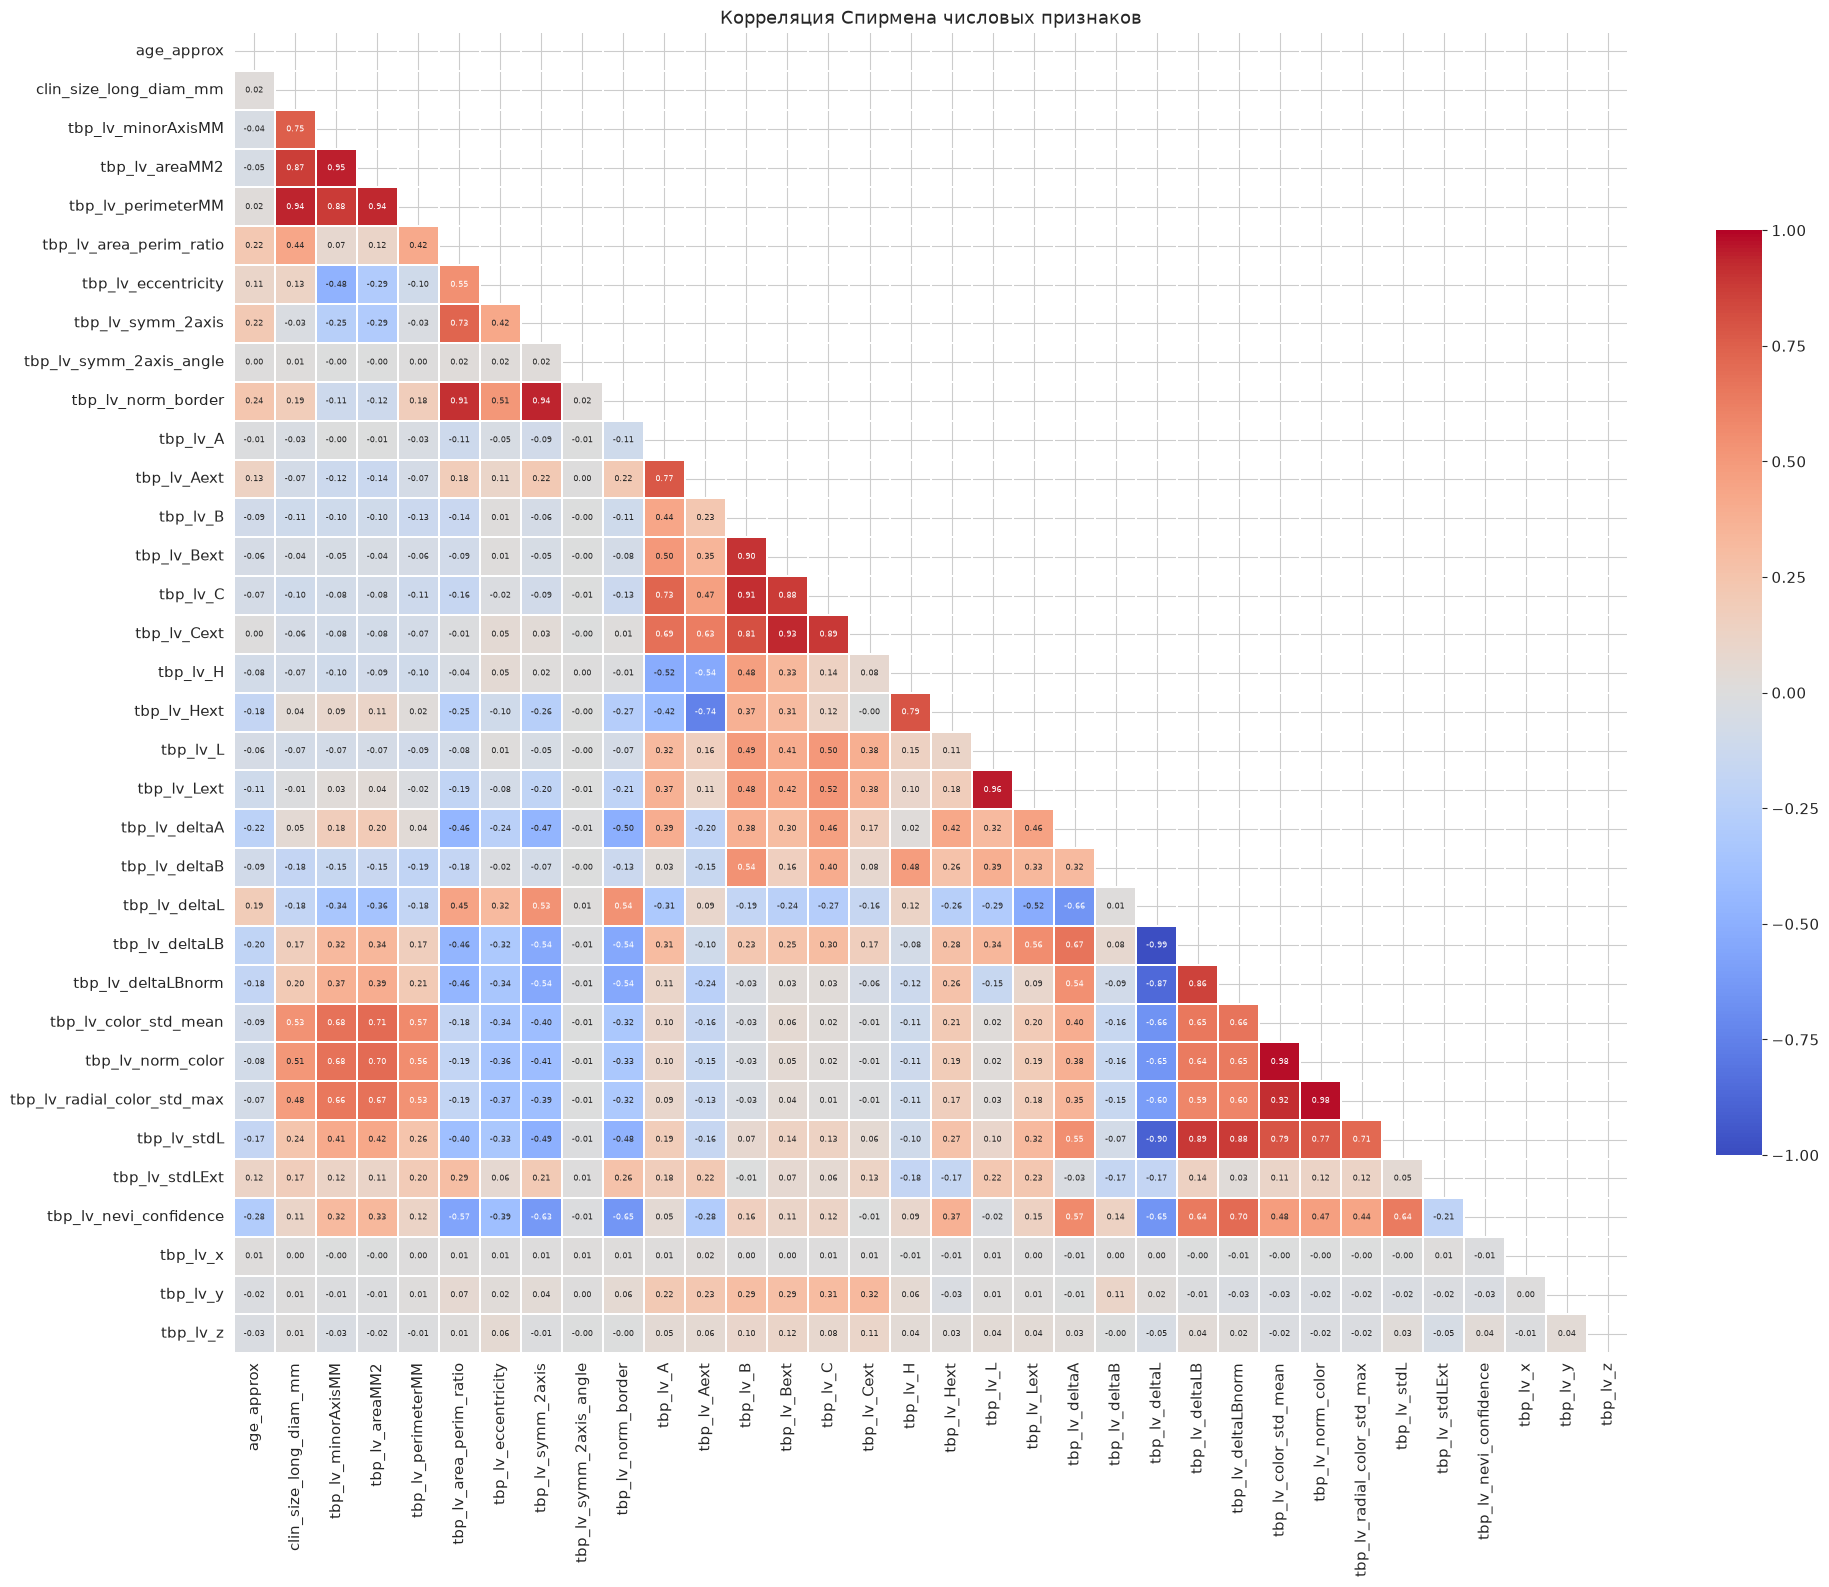

In [30]:
# 7.1 Корреляционная матрица (Spearman через ранги — быстро на 400k строк)
corr = df[NUM_FEATURES].rank().corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(20, 16))
sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'size': 6}, linewidths=0.3, cbar_kws={'shrink': 0.7})
plt.title('Корреляция Спирмена числовых признаков')
plt.tight_layout()
save_fig('07_corr_matrix')
plt.show()

In [31]:
# 7.2 Пары с |rho| >= 0.9 и ключевая "геометрическая" группа
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().reset_index()
pairs.columns = ['feature_1', 'feature_2', 'rho']
pairs['abs_rho'] = pairs['rho'].abs()
high_pairs = pairs[pairs['abs_rho'] >= 0.90].sort_values('abs_rho', ascending=False).reset_index(drop=True)
print(f'Пар признаков с |rho| >= 0.90: {len(high_pairs)} из {len(pairs)}')
display(high_pairs)

geom_key = ['clin_size_long_diam_mm', 'tbp_lv_minorAxisMM', 'tbp_lv_areaMM2', 'tbp_lv_perimeterMM']
print('\nКорреляция размерных признаков:')
display(corr.loc[geom_key, geom_key])

Пар признаков с |rho| >= 0.90: 13 из 561


,feature_1,feature_2,rho,abs_rho
0,tbp_lv_deltaL,tbp_lv_deltaLB,-0.9872,0.9872
1,tbp_lv_color_std_mean,tbp_lv_norm_color,0.9800,0.9800
2,tbp_lv_norm_color,tbp_lv_radial_color_std_max,0.9786,0.9786
3,tbp_lv_L,tbp_lv_Lext,0.9601,0.9601
4,tbp_lv_minorAxisMM,tbp_lv_areaMM2,0.9526,0.9526
5,clin_size_long_diam_mm,tbp_lv_perimeterMM,0.9423,0.9423
6,tbp_lv_symm_2axis,tbp_lv_norm_border,0.9416,0.9416
7,tbp_lv_areaMM2,tbp_lv_perimeterMM,0.9357,0.9357
8,tbp_lv_Bext,tbp_lv_Cext,0.9342,0.9342
9,tbp_lv_color_std_mean,tbp_lv_radial_color_std_max,0.9202,0.9202



Корреляция размерных признаков:


,clin_size_long_diam_mm,tbp_lv_minorAxisMM,tbp_lv_areaMM2,tbp_lv_perimeterMM
clin_size_long_diam_mm,1.0000,0.7518,0.8744,0.9423
tbp_lv_minorAxisMM,0.7518,1.0000,0.9526,0.8815
tbp_lv_areaMM2,0.8744,0.9526,1.0000,0.9357
tbp_lv_perimeterMM,0.9423,0.8815,0.9357,1.0000


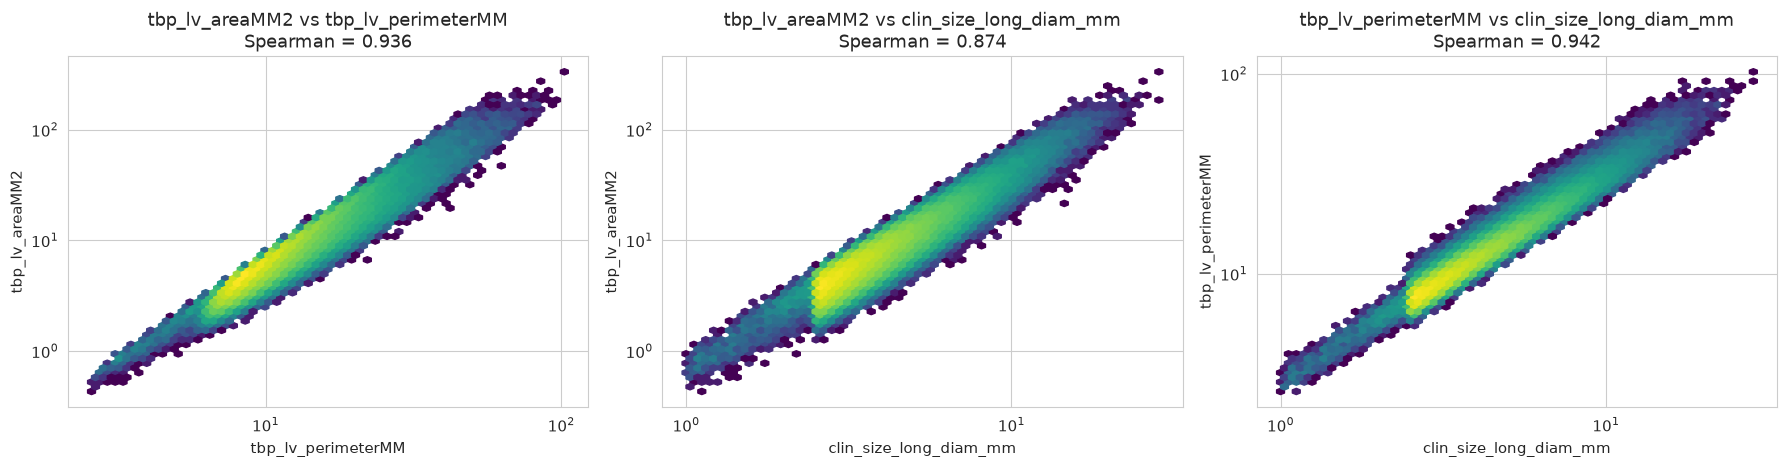

,pearson
"corr(hypot(A, B), C)",1.0000
"corr(hypot(Aext, Bext), Cext)",1.0000
"corr(A - Aext, deltaA)",1.0000
"corr(B - Bext, deltaB)",1.0000
"corr(L - Lext, deltaL)",1.0000
"corr(hypot(deltaL, deltaB), deltaLB)",0.9996


In [32]:
# 7.3 Наглядно: площадь <-> периметр <-> диаметр (hexbin, log-оси)
pos = (df['tbp_lv_areaMM2'] > 0) & (df['tbp_lv_perimeterMM'] > 0) & (df['clin_size_long_diam_mm'] > 0)
d = df.loc[pos]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (xc, yc) in zip(axes, [('tbp_lv_perimeterMM', 'tbp_lv_areaMM2'),
                               ('clin_size_long_diam_mm', 'tbp_lv_areaMM2'),
                               ('clin_size_long_diam_mm', 'tbp_lv_perimeterMM')]):
    hb = ax.hexbin(d[xc], d[yc], gridsize=60, bins='log', xscale='log', yscale='log', mincnt=1, cmap='viridis')
    ax.set_xlabel(xc)
    ax.set_ylabel(yc)
    ax.set_title(f'{yc} vs {xc}\nSpearman = {corr.loc[xc, yc]:.3f}')
plt.tight_layout()
save_fig('07_area_perimeter')
plt.show()

# Проверка гипотез о "производных" признаках: некоторые TBP-признаки являются функциями других
checks = pd.Series({
    'corr(hypot(A, B), C)': np.corrcoef(np.hypot(df['tbp_lv_A'], df['tbp_lv_B']), df['tbp_lv_C'])[0, 1],
    'corr(hypot(Aext, Bext), Cext)': np.corrcoef(np.hypot(df['tbp_lv_Aext'], df['tbp_lv_Bext']), df['tbp_lv_Cext'])[0, 1],
    'corr(A - Aext, deltaA)': np.corrcoef(df['tbp_lv_A'] - df['tbp_lv_Aext'], df['tbp_lv_deltaA'])[0, 1],
    'corr(B - Bext, deltaB)': np.corrcoef(df['tbp_lv_B'] - df['tbp_lv_Bext'], df['tbp_lv_deltaB'])[0, 1],
    'corr(L - Lext, deltaL)': np.corrcoef(df['tbp_lv_L'] - df['tbp_lv_Lext'], df['tbp_lv_deltaL'])[0, 1],
    'corr(hypot(deltaL, deltaB), deltaLB)': np.corrcoef(np.hypot(df['tbp_lv_deltaL'], df['tbp_lv_deltaB']), df['tbp_lv_deltaLB'])[0, 1],
}, name='pearson')
checks.to_frame()

In [33]:
# 7.4 Кластеризация признаков по |rho| и выбор представителя (по ROC AUC одного признака)
CORR_THR = 0.90

dist = 1 - corr.abs().to_numpy()
np.fill_diagonal(dist, 0)
dist = np.clip((dist + dist.T) / 2, 0, None)
Z = linkage(squareform(dist, checks=False), method='average')
cluster_id = fcluster(Z, t=1 - CORR_THR, criterion='distance')

cluster_rows, keep_features, drop_features = [], [], []
for cid in sorted(set(cluster_id)):
    members = [f for f, c in zip(corr.columns, cluster_id) if c == cid]
    keep = max(members, key=lambda f: auc_map[f])
    keep_features.append(keep)
    drop_features += [f for f in members if f != keep]
    if len(members) > 1:
        cluster_rows.append({'cluster': cid, 'size': len(members), 'keep (max AUC)': keep,
                             'drop': ', '.join(f for f in members if f != keep)})
cluster_df = pd.DataFrame(cluster_rows)
display(cluster_df)
print(f'\nБыло признаков: {len(NUM_FEATURES)} -> после удаления дублей (порог |rho| >= {CORR_THR}): {len(keep_features)}')
print('Рекомендуется удалить:', drop_features)

pd.DataFrame({'feature': NUM_FEATURES,
              'action': ['keep' if f in keep_features else 'drop (collinear)' for f in NUM_FEATURES]}
             ).to_csv(CSV_DIR / 'isic2024_feature_pruning_plan.csv', index=False)

,cluster,size,keep (max AUC),drop
0,5,2,tbp_lv_L,tbp_lv_Lext
1,6,2,tbp_lv_Bext,tbp_lv_Cext
2,7,2,tbp_lv_B,tbp_lv_C
3,10,2,tbp_lv_minorAxisMM,tbp_lv_areaMM2
4,11,2,tbp_lv_perimeterMM,clin_size_long_diam_mm
5,12,3,tbp_lv_radial_color_std_max,"tbp_lv_color_std_mean, tbp_lv_norm_color"
6,13,2,tbp_lv_deltaLB,tbp_lv_deltaL
7,17,2,tbp_lv_norm_border,tbp_lv_symm_2axis



Было признаков: 34 -> после удаления дублей (порог |rho| >= 0.9): 25
Рекомендуется удалить: ['tbp_lv_Lext', 'tbp_lv_Cext', 'tbp_lv_C', 'tbp_lv_areaMM2', 'clin_size_long_diam_mm', 'tbp_lv_color_std_mean', 'tbp_lv_norm_color', 'tbp_lv_deltaL', 'tbp_lv_symm_2axis']


VIF > 10: до = 24 признаков, после = 11 признаков


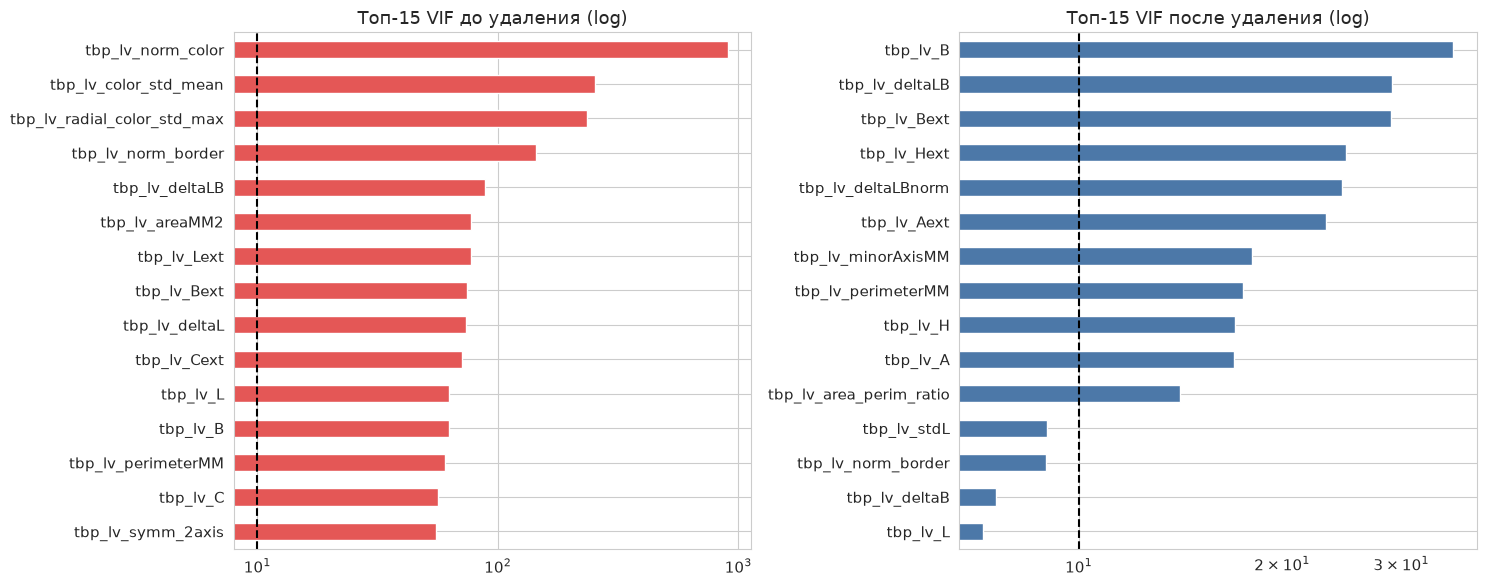

In [34]:
# 7.5 VIF до / после удаления (VIF_i = диагональ обратной корреляционной матрицы)
def vif_from_corr(c):
    inv = np.linalg.pinv(c.fillna(0).to_numpy())
    return pd.Series(np.diag(inv), index=c.columns)


vif_before = vif_from_corr(corr).sort_values(ascending=False)
vif_after = vif_from_corr(corr.loc[keep_features, keep_features]).sort_values(ascending=False)
print(f'VIF > 10: до = {(vif_before > 10).sum()} признаков, после = {(vif_after > 10).sum()} признаков')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
vif_before.head(15)[::-1].plot(kind='barh', ax=axes[0], color='#E45756')
axes[0].axvline(10, c='k', ls='--')
axes[0].set_xscale('log')
axes[0].set_title('Топ-15 VIF до удаления (log)')
vif_after.head(15)[::-1].plot(kind='barh', ax=axes[1], color='#4C78A8')
axes[1].axvline(10, c='k', ls='--')
axes[1].set_xscale('log')
axes[1].set_title('Топ-15 VIF после удаления (log)')
plt.tight_layout()
save_fig('07_vif')
plt.show()

### Выводы по разделу 7

* Размерные признаки (`clin_size_long_diam_mm`, `tbp_lv_minorAxisMM`, `tbp_lv_areaMM2`, `tbp_lv_perimeterMM`) сильно взаимосвязаны: площадь ~ квадрат линейного размера, периметр ~ линейный размер. Это видно на hexbin-графиках 7.3.
* Многие цветовые признаки — **производные друг от друга**: `C` ≈ √(A²+B²) (цветовая насыщенность), `delta*` = разность значения очага и окружающей кожи (`A − Aext` и т. д.), `deltaLB` ≈ √(ΔL²+ΔB²) — корреляции проверены в 7.3. Таблица 7.4 группирует такие признаки в кластеры.
* Из каждого кластера оставляем один представитель с лучшей одномерной разделяющей способностью (`csv_outputs/isic2024_feature_pruning_plan.csv`); VIF после отбора заметно падает (7.5).
* Деревья устойчивы к мультиколлинеарности по качеству предсказаний, но (а) важности признаков «размазываются» между дублями, (б) обучение дольше, (в) шум в отборе фич. Удаление дублей — дешёвая гигиена; при желании можно сначала сравнить CV с полным и сокращённым набором.
* Порог 0.9 и выбор по AUC — эвристика: окончательный набор лучше подтвердить на `StratifiedGroupKFold`. Инженерные отношения (например, `diameter / minorAxis`) могут оказаться полезнее исходных коррелированных пар.

---
## 8. Групповой анализ «Гадкого утёнка» (Contextual EDA)

Дерматологическое правило *«ugly duckling»*: у человека родинки обычно похожи друг на друга, а **злокачественный очаг выделяется на фоне остальных**.
Считаем для каждой родинки отклонение признака от значений *внутри её пациента*:

* `diff_mean`, `diff_median` — разность с средним / медианой пациента;
* `ratio_median` — отношение к медиане (только для размерных признаков);
* `z` — стандартизованное отклонение `(x − mean) / std` внутри пациента;
* `pct_rank` — процентильный ранг родинки среди очагов пациента.

Агрегаты строятся **только из признаков (без target)**, а пациент целиком лежит в одном фолде → утечки таргета нет. На тесте их можно считать так же, группируя по `patient_id` тестовой выборки.

In [35]:
# 8.1 Построение признаков "относительно пациента"
DUCK_FEATURES = ['clin_size_long_diam_mm', 'tbp_lv_areaMM2', 'tbp_lv_perimeterMM', 'tbp_lv_minorAxisMM',
                 'tbp_lv_L', 'tbp_lv_A', 'tbp_lv_B', 'tbp_lv_C', 'tbp_lv_H',
                 'tbp_lv_deltaLBnorm', 'tbp_lv_norm_color', 'tbp_lv_norm_border', 'tbp_lv_color_std_mean',
                 'tbp_lv_symm_2axis', 'tbp_lv_eccentricity', 'tbp_lv_nevi_confidence',
                 'tbp_lv_radial_color_std_max', 'tbp_lv_stdL']
SIZE_FEATURES = ['clin_size_long_diam_mm', 'tbp_lv_areaMM2', 'tbp_lv_perimeterMM', 'tbp_lv_minorAxisMM']
MIN_LESIONS = 5          # отклонение от "нормы пациента" осмысленно, только если у пациента есть из чего считать

grp = df.groupby('patient_id')
n_per_patient = grp[TARGET].transform('size')

duck = {}
for f in DUCK_FEATURES:
    g = grp[f]
    mean_, med_, std_ = g.transform('mean'), g.transform('median'), g.transform('std')
    duck[f'{f}__diff_mean'] = df[f] - mean_
    duck[f'{f}__diff_median'] = df[f] - med_
    duck[f'{f}__z'] = (df[f] - mean_) / std_.replace(0, np.nan)
    duck[f'{f}__pct_rank'] = g.rank(pct=True)
    if f in SIZE_FEATURES:
        duck[f'{f}__ratio_median'] = df[f] / med_.replace(0, np.nan)
df_duck = pd.DataFrame(duck)

valid = (n_per_patient >= MIN_LESIONS).to_numpy()
print(f'Создано признаков "гадкого утёнка": {df_duck.shape[1]}')
print(f'Строк с пациентом, у которого >= {MIN_LESIONS} очагов: {valid.sum():,} ({valid.mean():.2%}); меланом среди них: {int(y[valid].sum())} из {n_pos}')
df_duck[[c for c in df_duck.columns if c.startswith('clin_size_long_diam_mm')]].describe().T

Создано признаков "гадкого утёнка": 76
Строк с пациентом, у которого >= 5 очагов: 401,042 (100.00%); меланом среди них: 392 из 393


,count,mean,std,min,25%,50%,75%,max
clin_size_long_diam_mm__diff_mean,"401,059.0000",-0.0000,1.6983,-5.4966,-1.0122,-0.4938,0.4527,24.2842
clin_size_long_diam_mm__diff_median,"401,059.0000",0.5304,1.7060,-5.3300,-0.5000,0.0000,0.9650,24.9000
clin_size_long_diam_mm__z,"401,054.0000",-0.0000,0.9987,-3.0468,-0.6445,-0.3193,0.2902,14.1247
clin_size_long_diam_mm__pct_rank,"401,059.0000",0.5013,0.2886,0.0001,0.2512,0.5014,0.7512,1.0000
clin_size_long_diam_mm__ratio_median,"401,059.0000",1.1548,0.4916,0.1730,0.8485,1.0000,1.2849,8.1143


,raw_auc,best_duck_auc,best_duck_kind,auc_gain,raw_pAUC,best_duck_pAUC,pAUC_gain
feature,,,,,,,
tbp_lv_L,0.5221,0.6518,z,0.1297,0.0240,0.0435,0.0195
tbp_lv_deltaLBnorm,0.5481,0.6092,diff_median,0.0611,0.0049,0.0146,0.0097
tbp_lv_stdL,0.5592,0.6040,diff_median,0.0448,0.0124,0.0237,0.0113
tbp_lv_areaMM2,0.6171,0.6465,diff_mean,0.0294,0.0004,0.0124,0.0120
tbp_lv_color_std_mean,0.6089,0.6291,pct_rank,0.0203,0.0057,0.0094,0.0037
tbp_lv_eccentricity,0.5522,0.5718,diff_median,0.0196,0.0270,0.0288,0.0018
tbp_lv_norm_color,0.6146,0.6325,pct_rank,0.0179,0.0057,0.0092,0.0036
tbp_lv_radial_color_std_max,0.6150,0.6317,pct_rank,0.0167,0.0064,0.0103,0.0040
tbp_lv_minorAxisMM,0.6264,0.6402,diff_mean,0.0138,0.0012,0.0042,0.0030


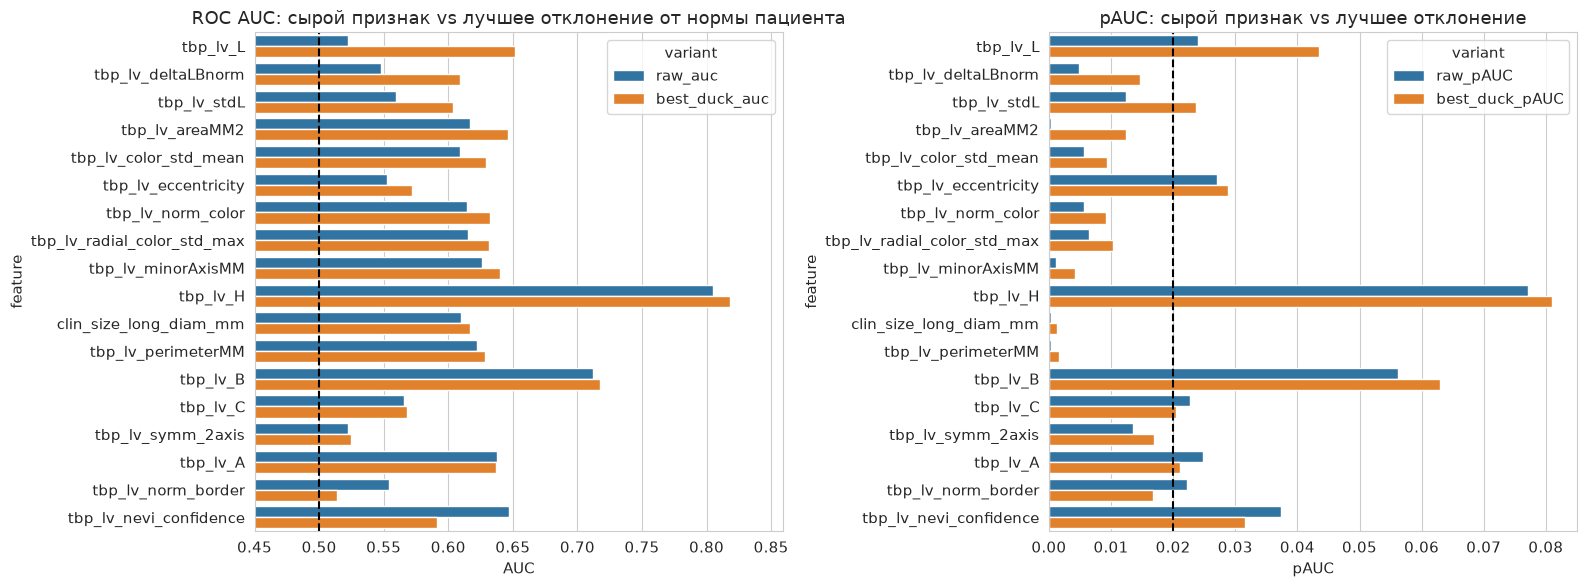

In [36]:
# 8.2 Что лучше разделяет классы: "сырой" признак или его отклонение от нормы пациента?
duck_rows = []
yv = y[valid]
for f in DUCK_FEATURES:
    a_raw, _, p_raw = univariate_scores(yv, df[f].to_numpy(dtype=float)[valid])
    row = {'feature': f, 'raw_auc': a_raw, 'raw_pAUC': p_raw}
    for kind in ['diff_mean', 'diff_median', 'z', 'pct_rank']:
        a, _, p = univariate_scores(yv, df_duck[f'{f}__{kind}'].to_numpy(dtype=float)[valid])
        row[f'{kind}_auc'] = a
        row[f'{kind}_pAUC'] = p
    duck_rows.append(row)
duck_eval = pd.DataFrame(duck_rows).set_index('feature')

auc_cols = ['diff_mean_auc', 'diff_median_auc', 'z_auc', 'pct_rank_auc']
duck_eval['best_duck_auc'] = duck_eval[auc_cols].max(axis=1)
duck_eval['best_duck_kind'] = duck_eval[auc_cols].idxmax(axis=1).str.replace('_auc', '')
duck_eval['auc_gain'] = duck_eval['best_duck_auc'] - duck_eval['raw_auc']
duck_eval['best_duck_pAUC'] = duck_eval[[c.replace('_auc', '_pAUC') for c in auc_cols]].max(axis=1)
duck_eval['pAUC_gain'] = duck_eval['best_duck_pAUC'] - duck_eval['raw_pAUC']
duck_eval = duck_eval.sort_values('auc_gain', ascending=False)
duck_eval.to_csv(CSV_DIR / 'isic2024_ugly_duckling_eval.csv')
display(duck_eval[['raw_auc', 'best_duck_auc', 'best_duck_kind', 'auc_gain', 'raw_pAUC', 'best_duck_pAUC', 'pAUC_gain']])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_df = duck_eval.reset_index().melt(id_vars='feature', value_vars=['raw_auc', 'best_duck_auc'], var_name='variant', value_name='AUC')
sns.barplot(data=plot_df, y='feature', x='AUC', hue='variant', ax=axes[0])
axes[0].axvline(0.5, c='k', ls='--')
axes[0].set_xlim(0.45, None)
axes[0].set_title('ROC AUC: сырой признак vs лучшее отклонение от нормы пациента')
plot_df2 = duck_eval.reset_index().melt(id_vars='feature', value_vars=['raw_pAUC', 'best_duck_pAUC'], var_name='variant', value_name='pAUC')
sns.barplot(data=plot_df2, y='feature', x='pAUC', hue='variant', ax=axes[1])
axes[1].axvline(0.02, c='k', ls='--')
axes[1].set_title('pAUC: сырой признак vs лучшее отклонение')
plt.tight_layout()
save_fig('08_duckling_gain')
plt.show()

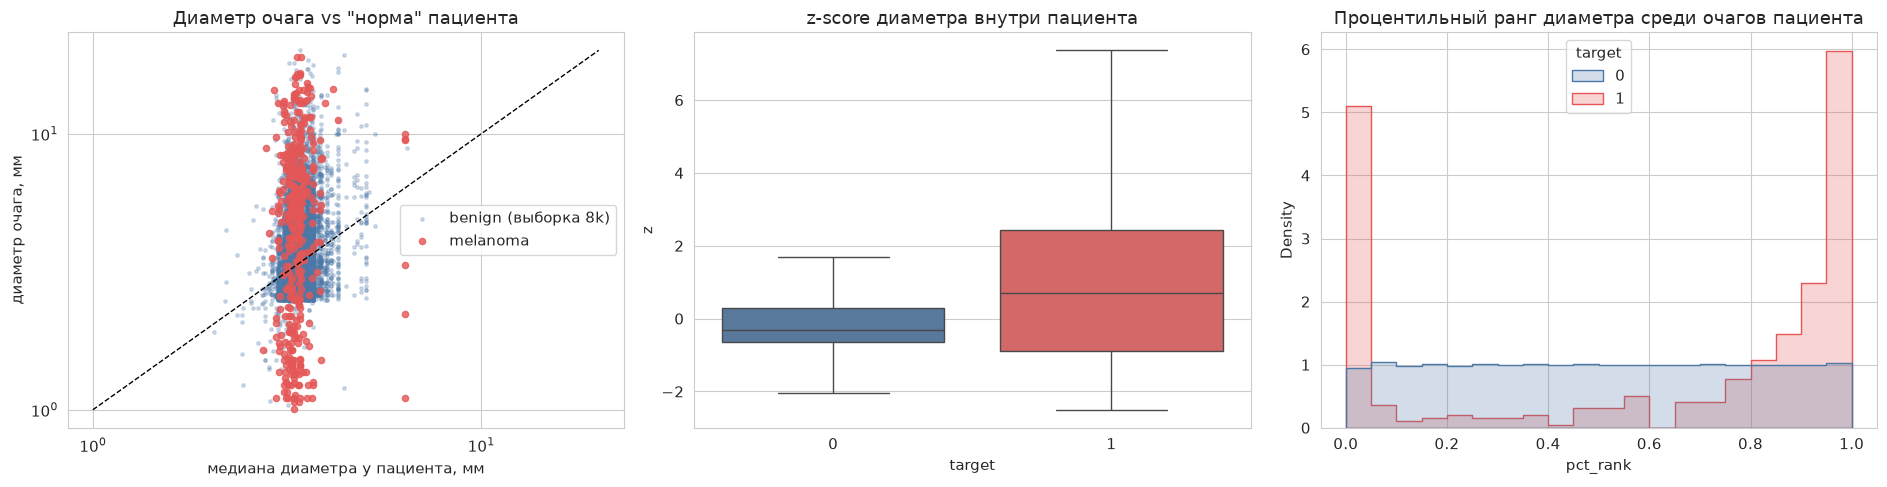

In [37]:
# 8.3 Визуализация на примере диаметра: относительно пациента меланомы "выскакивают"
diam_col = 'clin_size_long_diam_mm'
view = pd.DataFrame({'diam': df[diam_col], 'patient_median': grp[diam_col].transform('median'),
                     'z': df_duck[f'{diam_col}__z'], 'diff_median': df_duck[f'{diam_col}__diff_median'],
                     'pct_rank': df_duck[f'{diam_col}__pct_rank'], TARGET: y, 'valid': valid})
view = view[view['valid']]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sample = pd.concat([view[view[TARGET] == 1], view[view[TARGET] == 0].sample(8000, random_state=SEED)])
axes[0].scatter(sample.loc[sample[TARGET] == 0, 'patient_median'], sample.loc[sample[TARGET] == 0, 'diam'],
                s=6, alpha=0.25, c=PAL[0], label='benign (выборка 8k)')
axes[0].scatter(sample.loc[sample[TARGET] == 1, 'patient_median'], sample.loc[sample[TARGET] == 1, 'diam'],
                s=20, alpha=0.8, c=PAL[1], label='melanoma')
lim = [1, sample[['patient_median', 'diam']].max().max()]
axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('медиана диаметра у пациента, мм')
axes[0].set_ylabel('диаметр очага, мм')
axes[0].set_title('Диаметр очага vs "норма" пациента')
axes[0].legend()

sns.boxplot(data=view, x=TARGET, y='z', hue=TARGET, palette=PAL, showfliers=False, legend=False, ax=axes[1])
axes[1].set_title('z-score диаметра внутри пациента')
sns.histplot(data=view, x='pct_rank', hue=TARGET, stat='density', common_norm=False, bins=20,
             element='step', palette=PAL, ax=axes[2])
axes[2].set_title('Процентильный ранг диаметра среди очагов пациента')
plt.tight_layout()
save_fig('08_duckling_diameter')
plt.show()

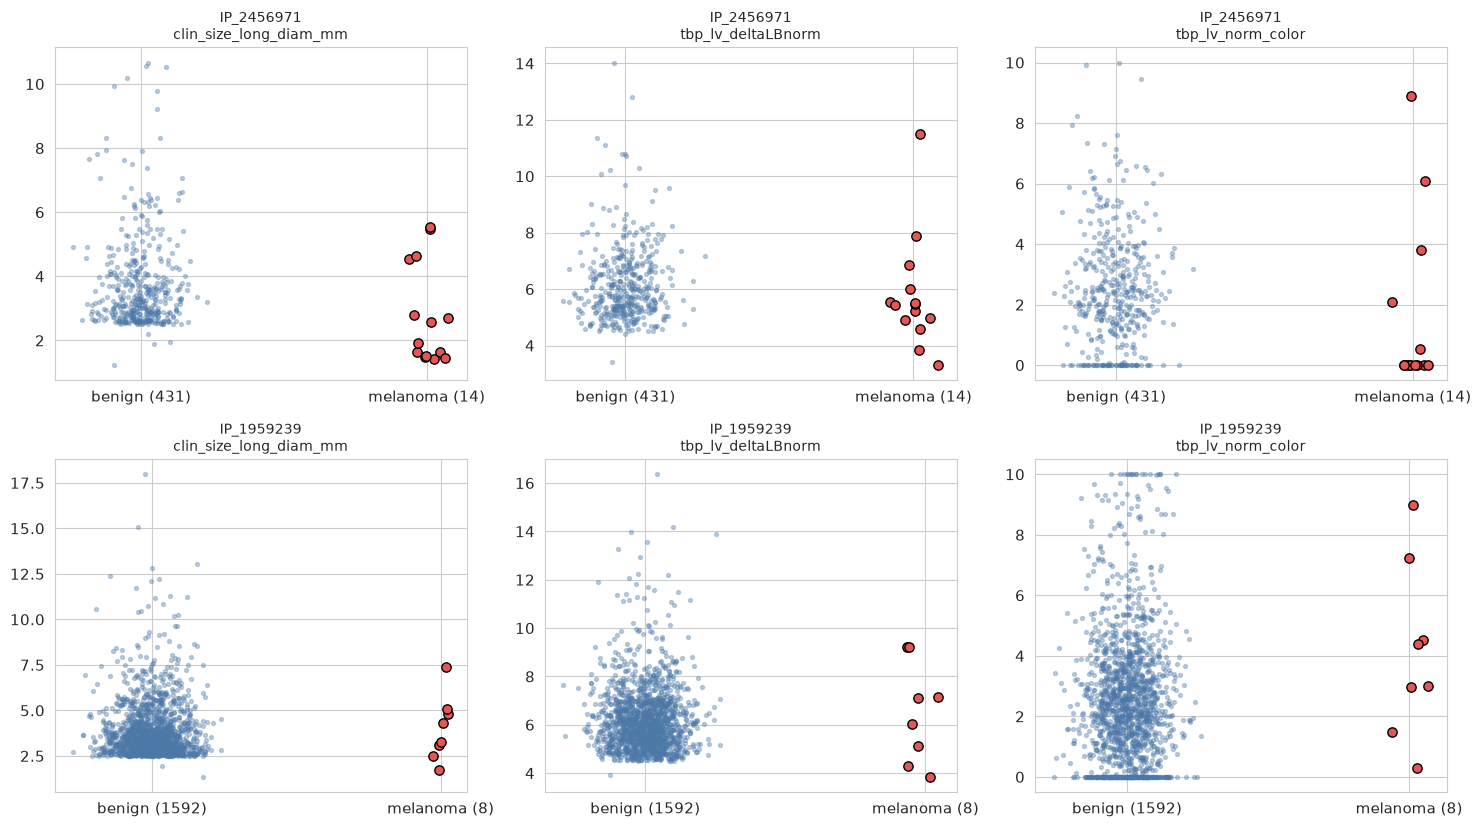

In [38]:
# 8.4 "Гадкий утёнок" на конкретных пациентах: меланомы (красные) на фоне остальных родинок того же человека
top_patients = patient.sort_values('n_melanoma', ascending=False).head(2)['patient_id'].tolist()
show_feats = ['clin_size_long_diam_mm', 'tbp_lv_deltaLBnorm', 'tbp_lv_norm_color']

fig, axes = plt.subplots(len(top_patients), len(show_feats), figsize=(5 * len(show_feats), 4.2 * len(top_patients)))
axes = np.atleast_2d(axes)
for i, pid in enumerate(top_patients):
    sub = df[df['patient_id'] == pid]
    b, m = sub[sub[TARGET] == 0], sub[sub[TARGET] == 1]
    for j, f in enumerate(show_feats):
        ax = axes[i, j]
        ax.scatter(RNG.normal(0, 0.08, len(b)), b[f], s=8, alpha=0.35, color=PAL[0])
        ax.scatter(RNG.normal(1, 0.04, len(m)), m[f], s=45, color=PAL[1], edgecolor='k')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([f'benign ({len(b)})', f'melanoma ({len(m)})'])
        ax.set_title(f'{pid}\n{f}', fontsize=10)
plt.tight_layout()
save_fig('08_duckling_patients')
plt.show()

### Выводы по разделу 8

* Признаки, нормированные на контекст пациента, часто дают **более высокий AUC/pAUC, чем сырые значения** (таблица 8.2, колонки `auc_gain`, `pAUC_gain`). Причина — различия между людьми (тип кожи, общий уровень пигментации, количество и размер родинок) маскируют сигнал «этот очаг не такой, как остальные».
* График 8.3 показывает, что меланомы лежат выше «нормы пациента» по размеру, а их процентильный ранг сдвинут к верхним значениям; на примерах 8.4 меланомы визуально выделяются на фоне родинок того же пациента — это и есть «гадкий утёнок».
* Для моделирования: добавлять в GBDT `diff_median`, `z`, `pct_rank` для размерных, цветовых и «неправильных» (asymmetry/border/color-irregularity) признаков; дополнительно можно подавать **агрегаты пациента** (mean/median/std/число очагов) и ранги внутри локализации.
* Важные оговорки: (а) для пациентов с малым числом очагов (< `MIN_LESIONS`) статистика ненадёжна; (б) в тесте пациенты могут быть представлены иным количеством кропов — нужно проверить стабильность; (в) агрегаты нельзя считать по train+test вместе без учёта групп.

---
## 9. Итоги и рекомендации для моделирования

In [39]:
# 9.1 Сводка ключевых чисел EDA (собирается автоматически из результатов выше)
top_feats = df_uni.head(5)[['feature', 'auc', 'pAUC']]
summary = {
    'Строк / пациентов': f'{n_total:,} / {n_patients}',
    'Меланом (доля)': f'{n_pos} ({PREVALENCE:.4%}), imbalance ≈ 1:{n_neg / n_pos:,.0f}',
    'Очагов на пациента (min / mean / median / max)': f'{patient.n_lesions.min()} / {patient.n_lesions.mean():.0f} / {patient.n_lesions.median():.0f} / {patient.n_lesions.max()}',
    'Пациентов-выбросов (Тьюки)': f'{int(patient.is_outlier.sum())} (дают {patient.loc[patient.is_outlier, "n_lesions"].sum() / n_total:.1%} строк)',
    'Пациентов с меланомой': f'{n_mel_patients} ({n_mel_patients / n_patients:.1%})',
    'Общих пациентов в train/valid: StratifiedKFold vs SGKF': f'{rep_skf.shared_patients.mean():.0f} vs {rep_sgkf.shared_patients.mean():.0f} (в среднем на фолд)',
    'Признаков до / после удаления коллинеарных': f'{len(NUM_FEATURES)} -> {len(keep_features)}',
    'Лучшие одиночные признаки (AUC)': ', '.join(f'{r.feature} ({r.auc:.3f})' for r in top_feats.itertuples()),
    'Лучший прирост от "гадкого утёнка" (AUC)': f'{duck_eval.index[0]}: {duck_eval.iloc[0]["raw_auc"]:.3f} -> {duck_eval.iloc[0]["best_duck_auc"]:.3f}',
}
for k, v in summary.items():
    print(f'• {k:55s}: {v}')

• Строк / пациентов                                      : 401,059 / 1042
• Меланом (доля)                                         : 393 (0.0980%), imbalance ≈ 1:1,020
• Очагов на пациента (min / mean / median / max)         : 1 / 385 / 242 / 9184
• Пациентов-выбросов (Тьюки)                             : 62 (дают 28.0% строк)
• Пациентов с меланомой                                  : 259 (24.9%)
• Общих пациентов в train/valid: StratifiedKFold vs SGKF : 1032 vs 0 (в среднем на фолд)
• Признаков до / после удаления коллинеарных             : 34 -> 25
• Лучшие одиночные признаки (AUC)                        : tbp_lv_H (0.805), tbp_lv_deltaB (0.754), tbp_lv_B (0.712), tbp_lv_Hext (0.720), tbp_lv_stdLExt (0.662)
• Лучший прирост от "гадкого утёнка" (AUC)               : tbp_lv_L: 0.522 -> 0.652


### Рекомендации по пайплайну

| Тема | Решение |
|---|---|
| **Валидация** | `StratifiedGroupKFold(5, groups=patient_id)`; готовое разбиение — `csv_outputs/folds_stratified_group_kfold.csv`. Усреднять по нескольким сидам; ориентироваться на pAUC (TPR ≥ 80 %) и сопровождать ROC AUC |
| **Дисбаланс** | undersampling негативов (≈ 1:10…1:50 с повторными сидами для bagging), `scale_pos_weight`; для ранговой метрики калибровка не нужна |
| **Утечки** | Исключить `lesion_id`, `iddx_*`, `mel_*`, `tbp_lv_dnn_lesion_confidence` (train-only / «знают» ответ) |
| **Пропуски** | Оставить NaN для GBDT; `isna`-флаги только для `age/sex/site`; `sex` и `site` можно восстановить по пациенту / `tbp_lv_location_simple` |
| **Коллинеарность** | Убрать дубли по плану `isic2024_feature_pruning_plan.csv`; добавить осмысленные отношения (`diameter / minorAxis`, `perimeter² / area`) |
| **Контекст пациента** | Добавить признаки «гадкого утёнка» (diff/z/pct_rank внутри `patient_id`) и агрегаты пациента (mean / std / число очагов) |
| **Пациенты-выбросы** | Рассмотреть веса `1 / n_lesions` или ограничение числа негативов на пациента |
| **Домен-шифт** | Источники (`attribution`) различаются по частоте меланом; следить, чтобы модель не училась на «источнике» |
| **Изображения** | Метаданные — лишь часть сигнала; финальное решение — ансамбль GBDT (табличные признаки) + CNN/ViT по кропам |